# ขั้นที่ 2: Feature ภูมิประเทศ ธรณีวิทยา และดาวเทียม

ต่อจากขั้นที่ 1 (พันเจีย) ใช้ชุดจุดเดียวกัน (`data/features/points.parquet`: แหล่ง ทธ. 518, PBDB 290, background 2 ชุด × 5,000)

| กลุ่ม | ที่มา | feature | เหตุผล (อ้างอิง) |
|---|---|---|---|
| `dem_` | Copernicus DEM GLO-30 | ความสูง, ความลาดชัน, TPI, ความขรุขระ ที่จุด / 1 กม. / 5 กม. | ความลาดชัน = การกัดเซาะที่ทำให้ซากโผล่ (Block et al. 2016, discovery model) |
| `geo_` | แผนที่หน่วยหิน 1:250,000 + ถ้ำ (ทธ.) | หน่วยหิน/ยุค ณ จุด, สัดส่วนยุคหินในรัศมี 5 กม., ระยะถึงหินแต่ละยุค, ระยะถึงถ้ำ | ซากอยู่ในหินตะกอนยุคที่ถูกต้อง (Block 2016 preservation model); ถ้ำ = หินปูน/ซากควอเทอร์นารี |
| `oc_` | หินโผล่ (ทธ.) | ระยะถึงหินโผล่/หินคาร์บอเนตโผล่, ชนิดหินโผล่ที่ใกล้สุด, อยู่ในจังหวัดที่สำรวจไหม | **แยกกลุ่ม** เพราะมาจากการสำรวจแค่ ~10 จังหวัด (ทดสอบในขั้นโมเดลว่าช่วยจริงหรือแค่ความลำเอียง) |
| `s2_` | Sentinel-2 L2A 20 ม., patch 32×32 px (640 ม.) | ค่าสะท้อน 6 แบนด์, NDVI, ดินโล่ง, SWIR ratio (ดินเหนียว/คาร์บอเนต), iron oxide | สเปกตรัมของแหล่งฟอสซิล (Emerson et al. 2015 ใช้ Landsat แบนด์ 2–7 รวม SWIR) |

**คำตอบจากการถามตอบ**: DEM หลายระดับ (จุด + 1 + 5 กม.), ธรณีวิทยาทั้ง 4 แบบ, หินโผล่ใช้แต่แยกกลุ่ม,
Sentinel-2 ความละเอียด 20 ม. ครบทุกจุด, โค้ด feature อยู่ใน notebook นี้และถูกเขียนออกเป็น `notebooks/feature_lib.py` สำหรับขั้นทำนาย

**แหล่งภาพ Sentinel-2**: Microsoft Planetary Computer (`sentinel-2-l2a`) เพราะ Earth Search (AWS สหรัฐฯ) ดาวน์โหลดได้ต่ำกว่า 0.2 MB/s จากเครือข่ายนี้
ใช้กติกาเลือกภาพเดียวกันทั้งตอน train และตอนทำนาย: ภาพหน้าแล้ง (พ.ย.–มี.ค. 2024/25–2025/26) เมฆทั้งภาพ < 40%
เรียงตามเมฆน้อย→มาก เลือกภาพแรกที่ patch มีเมฆ/เงาเมฆ ≤ 5% (ตรวจจากชั้น SCL)

**รันต่อเมื่อหยุดกลางทาง**: ทุกขั้นบันทึก cache ทีละ chunk (`data/features/sat_cache/`), patch Sentinel-2 บันทึกทีละจุด (`data/features/s2/patches/`)
รันซ้ำจะข้ามส่วนที่เสร็จแล้ว การดึงภาพครั้งแรกใช้สคริปต์ `scripts/fetch_s2_patches.py` (เรียกฟังก์ชันชุดเดียวกับ notebook นี้)

In [1]:
import sys
import time

import matplotlib.pyplot as plt
from matplotlib import font_manager
from sklearn.metrics import roc_auc_score

_installed = {f.name for f in font_manager.fontManager.ttflist}
THAI_FONT = next((f for f in ["Tahoma", "Thonburi", "Noto Sans Thai", "Leelawadee UI", "Loma", "Garuda"] if f in _installed), None)
plt.rcParams.update({
    "font.family": [THAI_FONT, "DejaVu Sans"] if THAI_FONT else ["DejaVu Sans"], "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#8a8984", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6, "axes.axisbelow": True,
})
INK, MUTED = "#52514e", "#8a8984"
SOURCE_COLOR = {"dmr_site": "#2a78d6", "pbdb": "#eb6834", "bg_uniform": "#bdbcb6", "bg_bias": "#1baf7a"}
GROUP_COLOR = {"pg_": "#4a3aa7", "dem_": "#eb6834", "geo_": "#1baf7a", "oc_": "#eda100", "s2_": "#2a78d6"}

## 1. โค้ดคำนวณ feature (`feature_lib`)

เซลล์ด้านล่างคือโค้ดชุดเดียวกับไฟล์ `notebooks/feature_lib.py` ทุกตัวอักษร (สร้างจาก `scripts/lib_sections/*.py`)
แก้ที่ `scripts/lib_sections/` แล้วรัน `scripts/run_satellite_nb.sh` ทั้ง notebook และไฟล์ .py จะอัปเดตพร้อมกัน

### `00_common.py`: ค่าคงที่และ path

In [2]:
# Shared paths, constants and small helpers for all feature groups.
import json
import logging
import os
import re
import warnings
from concurrent.futures import ThreadPoolExecutor, as_completed
from pathlib import Path

logging.disable(logging.CRITICAL)
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd

os.environ.update(GDAL_DISABLE_READDIR_ON_OPEN="EMPTY_DIR", GDAL_HTTP_MAX_RETRY="5", GDAL_HTTP_RETRY_DELAY="3",
                  GDAL_HTTP_TIMEOUT="60", GDAL_HTTP_CONNECTTIMEOUT="15", GDAL_CACHEMAX="2048",
                  CPL_VSIL_CURL_ALLOWED_EXTENSIONS=".tif", VSI_CACHE="TRUE", VSI_CACHE_SIZE="536870912",
                  GDAL_HTTP_MULTIPLEX="YES", GDAL_HTTP_VERSION="2")

ROOT = Path(__file__).resolve().parent.parent if "__file__" in globals() else Path.cwd().parent
DATA = ROOT / "data"
FEAT = DATA / "features"
EARTH_SEARCH = "https://earth-search.aws.element84.com/v1"
THAI_BBOX = (97.3, 5.6, 105.7, 20.5)


def tqdm_auto():
    from tqdm.auto import tqdm
    return tqdm

### `10_pangea.py`: พันเจีย (ใช้ตอนทำนายจุดใหม่ ตรรกะเดียวกับ notebook 08)

In [3]:
# Paleogeography (Pangea) features for arbitrary points: same logic as notebook 08
# (plate partition -> finite rotation per time -> PaleoDEM at the Scotese & Wright reconstructed position).
import glob as _glob

PG_TIMES = [480, 400, 300, 280, 270, 260, 250, 240, 230, 200, 150, 120, 66, 0]
PG_MODELS = {"sw18": "scotese_and_wright2018", "me21": "merdith2021"}


def plate_model_files(name):
    # ไฟล์ StaticPolygons / Rotations ของแบบจำลองแผ่นเปลือกโลก: ใช้ไฟล์ที่ดาวน์โหลดไว้ใน data/paleo ก่อน
    # (PlateModelManager จะเช็กเซิร์ฟเวอร์ GPlates ทุกครั้งแม้มีไฟล์แล้ว — ถ้าเซิร์ฟเวอร์ล่ม การทำนายพิกัดใหม่จะล้มทั้งที่ข้อมูลครบ)
    d = DATA / "paleo" / name
    static = sorted(_glob.glob(str(d / "StaticPolygons" / "*.gpml*")))
    rot = sorted(_glob.glob(str(d / "Rotations" / "*.rot")))
    if static and rot:
        return static, rot
    from plate_model_manager import PlateModelManager
    m = PlateModelManager().get_model(name, data_dir=str(DATA / "paleo"))     # ยังไม่มีไฟล์ -> ดาวน์โหลด
    return m.get_layer("StaticPolygons"), m.get_rotation_model()


class Pangea:
    def __init__(self):
        import pygplates
        self.pg = pygplates
        self.models = {}
        for key, name in PG_MODELS.items():
            static_files, rot_files = plate_model_files(name)
            static = pygplates.FeatureCollection()
            for f in static_files:
                static.add(pygplates.FeatureCollection(f))
            rot = pygplates.RotationModel(rot_files)
            self.models[key] = {"rot": rot, "part": pygplates.PlatePartitioner(static, rot)}
        self.dem_files = {}
        for f in _glob.glob(str(DATA / "paleo" / "paleodem_0.2deg" / "paleoDEM_0.2Deg_grids" / "*.nc")):
            self.dem_files[float(re.search(r"_([\d.]+)Ma\.nc$", f).group(1))] = f
        spec = json.loads((FEAT / "pangea_feature_list.json").read_text(encoding="utf-8"))
        self.columns = spec["numeric"] + [c for c in spec["categorical"] if c not in spec["numeric"]]

    def _dem_file(self, t):
        return self.dem_files[min(self.dem_files, key=lambda m: abs(m - t))]

    def features(self, lons, lats):
        import xarray as xr
        pg = self.pg
        lons, lats = np.asarray(lons, float), np.asarray(lats, float)
        out = pd.DataFrame(index=range(len(lons)))
        for key, mdl in self.models.items():
            plate, name, begin = [], [], []
            for lo, la in zip(lons, lats):
                poly = mdl["part"].partition_point(pg.PointOnSphere(la, lo))
                if poly is None:
                    plate.append(np.nan), name.append(None), begin.append(np.nan)
                else:
                    f = poly.get_feature()
                    plate.append(f.get_reconstruction_plate_id()), name.append(f.get_name()), begin.append(f.get_valid_time()[0])
            out[f"pg_{key}_plate"], out[f"pg_{key}_terrane"], out[f"pg_{key}_begin_ma"] = plate, name, begin
            plate_arr, begin_arr = np.asarray(plate, float), np.asarray(begin, float)
            pts = [pg.PointOnSphere(la, lo) for lo, la in zip(lons, lats)]
            for t in PG_TIMES:
                la_t, lo_t = np.full(len(lons), np.nan), np.full(len(lons), np.nan)
                for pid in np.unique(plate_arr[~np.isnan(plate_arr)]):
                    rot = mdl["rot"].get_rotation(float(t), int(pid))      # หนึ่ง rotation ต่อ (แผ่น, เวลา)
                    for i in np.nonzero((plate_arr == pid) & (begin_arr >= t))[0]:
                        la_t[i], lo_t[i] = (rot * pts[i]).to_lat_lon()
                out[f"pg_{key}_lat_{t}"], out[f"pg_{key}_lon_{t}"] = la_t, lo_t
                out[f"pg_{key}_abslat_{t}"] = np.abs(la_t)
            out[f"pg_{key}_drift_lat_250_0"] = out[f"pg_{key}_lat_0"] - out[f"pg_{key}_lat_250"]
        for t in PG_TIMES:
            z = np.full(len(lons), np.nan)
            ok = out[f"pg_sw18_lat_{t}"].notna().values
            if ok.any():
                with xr.open_dataset(self._dem_file(t)) as ds:
                    z[ok] = ds.z.interp(lat=xr.DataArray(out.loc[ok, f"pg_sw18_lat_{t}"].values, dims="p"),
                                        lon=xr.DataArray(out.loc[ok, f"pg_sw18_lon_{t}"].values, dims="p")).values
            out[f"pg_dem_{t}"] = z
            out[f"pg_marine_{t}"] = np.where(np.isnan(z), np.nan, (z < 0).astype(float))
        marine = out[[f"pg_marine_{t}" for t in PG_TIMES]]
        out["pg_n_marine"] = marine.sum(axis=1, min_count=1)
        out["pg_youngest_marine_ma"] = marine.apply(lambda r: min([t for t, v in zip(PG_TIMES, r.values) if v == 1], default=np.nan), axis=1)
        return out[[c for c in self.columns if c in out.columns]]

### `20_dem.py`: ภูมิประเทศจาก DEM

In [4]:
# Terrain features from Copernicus DEM GLO-30 (1 arc-second, EPSG:4326) at the point, 1 km and 5 km.
# Block et al. 2016 use slope as an erosion / exposure proxy ("discovery" model).
DEM_DIR = DATA / "dem" / "cop_dem_glo30"
DEM_RADII_KM = (1, 5)


class Dem:
    def __init__(self):
        self.tiles = {}
        for p in DEM_DIR.glob("*.tif"):
            m = re.search(r"_([NS])(\d+)_00_([EW])(\d+)_00_DEM", p.name)
            lat = int(m.group(2)) * (1 if m.group(1) == "N" else -1)
            lon = int(m.group(4)) * (1 if m.group(3) == "E" else -1)
            self.tiles[(lat, lon)] = p
        self._open = {}

    def _ds(self, key):
        import rasterio
        if key not in self._open:
            self._open[key] = rasterio.open(self.tiles[key])
        return self._open[key]

    def window(self, lon, lat, radius_km):
        # elevation array (float32, NaN outside tiles) covering a square of +-radius around the point, and its transform
        from rasterio.merge import merge
        dlat = radius_km / 110.574
        dlon = radius_km / (111.320 * np.cos(np.radians(lat)))
        b = (lon - dlon, lat - dlat, lon + dlon, lat + dlat)
        keys = [(la, lo) for la in range(int(np.floor(b[1])), int(np.floor(b[3])) + 1)
                for lo in range(int(np.floor(b[0])), int(np.floor(b[2])) + 1) if (la, lo) in self.tiles]
        if not keys:
            return None, None
        arr, tr = merge([self._ds(k) for k in keys], bounds=b, nodata=np.nan, dtype="float32")
        return arr[0], tr

    def features(self, lon, lat):
        z, tr = self.window(lon, lat, max(DEM_RADII_KM) + 0.2)
        keys = ["elev", "slope", "tpi_300m"] + [f"{s}_{r}km" for r in DEM_RADII_KM for s in ("mean", "std", "relief", "slope_mean", "slope_p90", "tpi")]
        if z is None or np.isnan(z).all():
            return {f"dem_{k}": np.nan for k in keys}
        res_x = tr.a * 111320 * np.cos(np.radians(lat))   # metres per pixel
        res_y = -tr.e * 110574
        gy, gx = np.gradient(np.where(np.isnan(z), np.nanmean(z), z), res_y, res_x)
        slope = np.degrees(np.arctan(np.hypot(gx, gy)))
        rows, cols = np.indices(z.shape)
        r0, c0 = (lat - tr.f) / tr.e, (lon - tr.c) / tr.a      # fractional pixel of the point
        dist_km = np.hypot((rows - r0) * res_y, (cols - c0) * res_x) / 1000
        ci, cj = int(np.clip(round(r0), 0, z.shape[0] - 1)), int(np.clip(round(c0), 0, z.shape[1] - 1))
        elev = float(z[ci, cj])
        near = dist_km <= 0.045                                  # ~3x3 px รอบจุด
        out = {"dem_elev": elev, "dem_slope": float(np.nanmean(slope[near])),
               "dem_tpi_300m": elev - float(np.nanmean(z[dist_km <= 0.3]))}
        for r in DEM_RADII_KM:
            m = dist_km <= r
            zz, ss = z[m], slope[m]
            out.update({f"dem_mean_{r}km": float(np.nanmean(zz)), f"dem_std_{r}km": float(np.nanstd(zz)),
                        f"dem_relief_{r}km": float(np.nanmax(zz) - np.nanmin(zz)),
                        f"dem_slope_mean_{r}km": float(np.nanmean(ss)), f"dem_slope_p90_{r}km": float(np.nanpercentile(ss, 90)),
                        f"dem_tpi_{r}km": elev - float(np.nanmean(zz))})
        return out

### `30_geology.py`: ธรณีวิทยา: หน่วยหิน, ถ้ำ, หินโผล่

In [5]:
# Geology features: DMR 1:250,000 rock units (at point, era share within 5 km, distance to each era),
# caves (CAVE_SURVEY, nationwide) and outcrops (OUT_CROP, only a few surveyed provinces -> separate "oc_" group).
GEO_DIR = DATA / "dmr_geology"
GEO_CACHE = FEAT / "geology_cache"
GEO_RES_M = 500                      # raster resolution for era share / distance (EPSG:32647)
GEO_SHARE_KM = 5
ERAS = ["Precambrian", "Cambrian", "Ordovician", "Silurian", "Devonian", "Carboniferous", "Permian",
        "Triassic", "Jurassic", "Cretaceous", "Tertiary", "Quaternary"]
_ERA_PREFIX = {"PE": ("Precambrian", "Precambrian"), "EO": ("Cambrian", "Ordovician"), "E": ("Cambrian", "Cambrian"),
               "O": ("Ordovician", "Ordovician"), "SDC": ("Silurian", "Carboniferous"), "SD": ("Silurian", "Devonian"),
               "DC": ("Devonian", "Carboniferous"), "D": ("Devonian", "Devonian"), "CP": ("Carboniferous", "Permian"),
               "C": ("Carboniferous", "Carboniferous"), "PTr": ("Permian", "Triassic"), "P": ("Permian", "Permian"),
               "TrJ": ("Triassic", "Jurassic"), "Tr": ("Triassic", "Triassic"), "JK": ("Jurassic", "Cretaceous"),
               "J": ("Jurassic", "Jurassic"), "KT": ("Cretaceous", "Tertiary"), "K": ("Cretaceous", "Cretaceous"),
               "T": ("Tertiary", "Tertiary"), "Q": ("Quaternary", "Quaternary")}
CARBONATE = ("limestone", "dolomite", "marble")


def symbol_era(sym):
    for p in sorted(_ERA_PREFIX, key=len, reverse=True):
        if isinstance(sym, str) and sym.startswith(p):
            return _ERA_PREFIX[p]
    return (None, None)


class Geology:
    def __init__(self):
        import geopandas as gpd
        from sklearn.neighbors import BallTree
        GEO_CACHE.mkdir(parents=True, exist_ok=True)
        legend = pd.read_csv(GEO_DIR / "rock_unit_250k_legend.csv", encoding="utf-8-sig")
        igneous_from = legend.loc[legend.TEXT_SYM.eq("Qgy"), "order"].iat[0]
        legend["rock_kind"] = np.where(legend.TEXT_SYM.eq("Water body"), "water",
                                       np.where(legend.order >= igneous_from, "igneous", "sedimentary/metamorphic"))
        rock = gpd.read_file(GEO_DIR / "rock_unit_250k.geojson")[["TEXT_SYM", "geometry"]].merge(
            legend[["TEXT_SYM", "rock_kind"]], on="TEXT_SYM", how="left")
        eras = rock.TEXT_SYM.map(symbol_era)
        rock["era_old"] = [e[0] for e in eras]
        rock["era_young"] = [e[1] for e in eras]
        self.rock = rock.to_crs(32647)
        self.rock_sindex = self.rock.sindex
        self._build_rasters()
        caves = gpd.read_file(GEO_DIR / "caves.geojson")
        self.cave_tree = BallTree(np.radians(np.c_[caves.geometry.y, caves.geometry.x]), metric="haversine")
        oc = gpd.read_file(GEO_DIR / "outcrops.geojson")
        oc = oc[oc.geometry.notna()]
        self.oc_rock = oc.RCKNAME.fillna("").str.lower().values
        self.oc_tree = BallTree(np.radians(np.c_[oc.geometry.y, oc.geometry.x]), metric="haversine")
        carb = np.array([any(k in r for k in CARBONATE) for r in self.oc_rock])
        self.oc_carb_tree = BallTree(np.radians(np.c_[oc.geometry.y[carb], oc.geometry.x[carb]]), metric="haversine")
        self.oc_provinces = set(oc.PROVINCE.dropna().str.strip()) - {""}
        prov = gpd.read_file(DATA / "dmr_admin" / "provinces.geojson")[["prov_nam_t", "geometry"]]
        self.prov = prov

    def _build_rasters(self):
        # era-of-unit raster (oldest era of each unit) and distance-to-era rasters, cached as .npz
        f = GEO_CACHE / f"era_raster_{GEO_RES_M}m.npz"
        if f.exists():
            z = np.load(f)
            self.era_grid, self.dist_grid, self.grid_origin = z["era"], z["dist"], tuple(z["origin"])
            return
        from rasterio import features as rfeat
        from rasterio.transform import from_origin
        from scipy.ndimage import distance_transform_edt
        x0, y0, x1, y1 = self.rock.total_bounds
        x0, y1 = np.floor(x0 / GEO_RES_M) * GEO_RES_M, np.ceil(y1 / GEO_RES_M) * GEO_RES_M
        w, h = int(np.ceil((x1 - x0) / GEO_RES_M)), int(np.ceil((y1 - y0) / GEO_RES_M))
        tr = from_origin(x0, y1, GEO_RES_M, GEO_RES_M)
        code = self.rock.era_old.map({e: i + 1 for i, e in enumerate(ERAS)}).fillna(0).astype(int)
        era = rfeat.rasterize(zip(self.rock.geometry, code), out_shape=(h, w), transform=tr, fill=0, dtype="uint8")
        dist = np.zeros((len(ERAS), h, w), dtype="float16")
        for i in range(len(ERAS)):
            mask = era == i + 1
            dist[i] = (distance_transform_edt(~mask) * GEO_RES_M / 1000).astype("float16") if mask.any() else np.float16(np.inf)
        np.savez_compressed(f, era=era, dist=dist, origin=np.array([x0, y1]))
        self.era_grid, self.dist_grid, self.grid_origin = era, dist, (x0, y1)

    def _rc(self, x, y):
        return int((self.grid_origin[1] - y) // GEO_RES_M), int((x - self.grid_origin[0]) // GEO_RES_M)

    def features(self, lons, lats):
        import geopandas as gpd
        from pyproj import Transformer
        lons, lats = np.asarray(lons, float), np.asarray(lats, float)
        xs, ys = Transformer.from_crs(4326, 32647, always_xy=True).transform(lons, lats)
        pts = gpd.GeoDataFrame(geometry=gpd.points_from_xy(xs, ys), crs=32647)
        j = gpd.sjoin(pts, self.rock, how="left", predicate="within")
        j = j[~j.index.duplicated()]
        out = pd.DataFrame({"geo_rock_sym": j.TEXT_SYM.fillna("none").values, "geo_era_old": j.era_old.fillna("none").values,
                            "geo_era_young": j.era_young.fillna("none").values, "geo_rock_kind": j.rock_kind.fillna("none").values})
        k = int(round(GEO_SHARE_KM * 1000 / GEO_RES_M))
        yy, xx = np.mgrid[-k:k + 1, -k:k + 1]
        disk = (yy ** 2 + xx ** 2) <= k * k
        H, W = self.era_grid.shape
        share = np.full((len(lons), len(ERAS)), np.nan)
        dist = np.full((len(lons), len(ERAS)), np.nan)
        for i, (x, y) in enumerate(zip(xs, ys)):
            r, c = self._rc(x, y)
            if not (0 <= r < H and 0 <= c < W):
                continue
            dist[i] = self.dist_grid[:, r, c].astype(float)
            r0, r1, c0, c1 = max(r - k, 0), min(r + k + 1, H), max(c - k, 0), min(c + k + 1, W)
            win = self.era_grid[r0:r1, c0:c1]
            m = disk[(r0 - r + k):(r1 - r + k), (c0 - c + k):(c1 - c + k)] & (win > 0)
            if m.any():
                share[i] = np.bincount(win[m], minlength=len(ERAS) + 1)[1:] / m.sum()
        for e_i, e in enumerate(ERAS):
            out[f"geo_share5_{e}"] = share[:, e_i]
            out[f"geo_dist_{e}_km"] = np.where(np.isinf(dist[:, e_i]), np.nan, dist[:, e_i])
        R = 6371.0
        q = np.radians(np.c_[lats, lons])
        out["geo_cave_dist_km"] = self.cave_tree.query(q, k=1)[0][:, 0] * R
        out["geo_cave_n5"] = self.cave_tree.query_radius(q, r=5 / R, count_only=True)
        d, idx = self.oc_tree.query(q, k=1)
        out["oc_dist_km"] = d[:, 0] * R
        out["oc_n5"] = self.oc_tree.query_radius(q, r=5 / R, count_only=True)
        out["oc_nearest_rock"] = self.oc_rock[idx[:, 0]]
        out["oc_carbonate_dist_km"] = self.oc_carb_tree.query(q, k=1)[0][:, 0] * R
        pj = gpd.sjoin(gpd.GeoDataFrame(geometry=gpd.points_from_xy(lons, lats), crs=4326), self.prov, how="left", predicate="within")
        pj = pj[~pj.index.duplicated()]
        out["oc_in_survey_prov"] = pj.prov_nam_t.fillna("").str.strip().isin(self.oc_provinces).astype(int).values
        return out

### `35_extra.py`:

In [6]:
# Extra feature layers for the feature-engineering experiments (notebooks 13-15).
# Every layer is a national raster on a 0.002° grid (~220 m) cached in data/features/extra_cache/*.npz and sampled at
# points, so training points, the 5 km grid and new coordinates get identical values.
#   gx_  geology+ : distance to faults / folds (DMR 1:250k, exported as images because the service returns no geometry),
#                   distance to rock-unit contacts, unit diversity, lithology / environment flags (ThaiLex)
#   pgx_ paleo    : signed distance to the paleo-coastline at each time slice (Scotese PaleoDEM, at paleo-coordinates)
#   lc_  surface  : ESA WorldCover fractions, JRC surface water, OSM rivers / streams / drainage density, TerraClimate
#   dc_  discovery: roads, quarries, DMR mineral-potential areas, reservoirs (where people dig — experiment only)
import io                 # json, re มาจาก 00_common

EXTRA_DIR = FEAT / "extra_cache"
X_RES = 0.002
X_W, X_S, X_E, X_N = THAI_BBOX
X_COLS, X_ROWS = int(round((X_E - X_W) / X_RES)), int(round((X_N - X_S) / X_RES))
KM_Y, KM_X = X_RES * 110.574, X_RES * 111.320 * np.cos(np.radians(13.0))     # ไทยอยู่ราว 6–20°N: คลาดไม่เกิน ~4%
_RASTERS = {}


def x_transform():
    from rasterio.transform import from_origin
    return from_origin(X_W, X_N, X_RES, X_RES)


def x_rc(lons, lats):
    r = np.clip(((X_N - np.asarray(lats, float)) / X_RES).astype(int), 0, X_ROWS - 1)
    c = np.clip(((np.asarray(lons, float) - X_W) / X_RES).astype(int), 0, X_COLS - 1)
    return r, c


def save_raster(name, arr):
    EXTRA_DIR.mkdir(parents=True, exist_ok=True)
    np.savez_compressed(EXTRA_DIR / f"{name}.npz", a=arr)
    _RASTERS[name] = arr


def load_raster(name):
    if name not in _RASTERS:
        _RASTERS[name] = np.load(EXTRA_DIR / f"{name}.npz")["a"]
    return _RASTERS[name]


def has_raster(name):
    return (EXTRA_DIR / f"{name}.npz").exists()


def dist_from_mask(mask):
    # km to the nearest True cell (float16 พอ: ความละเอียด ~0.1 กม. ที่ระยะ < 100 กม.)
    from scipy.ndimage import distance_transform_edt
    return distance_transform_edt(~mask, sampling=(KM_Y, KM_X)).astype("float16")


def rasterize_geoms(geoms, all_touched=True):
    from rasterio.features import rasterize
    return rasterize(((g, 1) for g in geoms if g is not None and not g.is_empty), out_shape=(X_ROWS, X_COLS),
                     transform=x_transform(), fill=0, all_touched=all_touched, dtype="uint8").astype(bool)


def sample_raster(name, lons, lats):
    r, c = x_rc(lons, lats)
    return load_raster(name)[r, c].astype("float32")


def window_mean(name, lons, lats, radius_px):
    # ค่าเฉลี่ยในหน้าต่าง (2r+1)^2 รอบจุด — ใช้ integral image ของทั้งประเทศ (เร็วกับหลายหมื่นจุด)
    key = f"__cum_{name}"
    if key not in _RASTERS:
        a = load_raster(name).astype("float64")
        _RASTERS[key] = np.pad(a.cumsum(0).cumsum(1), ((1, 0), (1, 0)))
    S = _RASTERS[key]
    r, c = x_rc(lons, lats)
    r0, r1 = np.clip(r - radius_px, 0, X_ROWS), np.clip(r + radius_px + 1, 0, X_ROWS)
    c0, c1 = np.clip(c - radius_px, 0, X_COLS), np.clip(c + radius_px + 1, 0, X_COLS)
    tot = S[r1, c1] - S[r0, c1] - S[r1, c0] + S[r0, c0]
    return (tot / ((r1 - r0) * (c1 - c0))).astype("float32")


def window_nunique(name, lons, lats, radius_px):
    a = load_raster(name)
    r, c = x_rc(lons, lats)
    out = np.empty(len(r), "float32")
    for i, (ri, ci) in enumerate(zip(r, c)):
        w = a[max(ri - radius_px, 0):ri + radius_px + 1, max(ci - radius_px, 0):ci + radius_px + 1]
        out[i] = len(np.unique(w[w > 0]))
    return out


# ---------------------------------------------------------------- builders (ใช้ครั้งเดียว แล้ว cache)
DMR_EXPORT = "https://gisportal.dmr.go.th/arcgis/rest/services/GEOL/GEOL_STR_250K/MapServer/export"
STRUCT_GROUPS = {"fault": ("0200", "0220"), "fold": ("0110", "0120", "0140")}     # STR_GRP_ID ตาม renderer ของ ทธ.


def build_structure(tile_px=2000, workers=6):
    import requests
    from concurrent.futures import ThreadPoolExecutor
    from PIL import Image
    tqdm = tqdm_auto()
    for kind, ids in STRUCT_GROUPS.items():
        name = f"gx_dist_{kind}_km"
        if has_raster(name):
            continue
        mask = np.zeros((X_ROWS, X_COLS), bool)
        where = "dmrdb2.DMRAPP.GEOL_STR_250K.STR_GRP_ID IN (" + ",".join(f"'{i}'" for i in ids) + ")"
        tiles = [(r0, c0) for r0 in range(0, X_ROWS, tile_px) for c0 in range(0, X_COLS, tile_px)]

        def get(rc):
            r0, c0 = rc
            h, w = min(tile_px, X_ROWS - r0), min(tile_px, X_COLS - c0)
            bbox = (X_W + c0 * X_RES, X_N - (r0 + h) * X_RES, X_W + (c0 + w) * X_RES, X_N - r0 * X_RES)
            p = {"bbox": ",".join(map(str, bbox)), "bboxSR": 4326, "imageSR": 4326, "size": f"{w},{h}", "format": "png",
                 "transparent": "true", "layers": "show:0", "f": "image", "dpi": 96, "layerDefs": json.dumps({"0": where})}
            for k in range(4):
                try:
                    r = requests.get(DMR_EXPORT, params=p, timeout=180)
                    img = np.array(Image.open(io.BytesIO(r.content)).convert("RGBA"))
                    return r0, c0, img[..., 3] > 0
                except Exception:                                   # noqa: BLE001
                    if k == 3:
                        raise
        with ThreadPoolExecutor(workers) as ex:
            for r0, c0, m in tqdm(ex.map(get, tiles), total=len(tiles), desc=f"ทธ. {kind}"):
                mask[r0:r0 + m.shape[0], c0:c0 + m.shape[1]] |= m
        save_raster(name, dist_from_mask(mask))


def build_rock_contacts():
    if has_raster("gx_dist_contact_km") and has_raster("gx_rock_code"):
        return
    import geopandas as gpd
    from rasterio.features import rasterize
    ru = gpd.read_file(DATA / "dmr_geology" / "rock_unit_250k.geojson")[["TEXT_SYM", "geometry"]].to_crs(4326)
    syms = sorted(ru.TEXT_SYM.dropna().unique())
    code = {s: i + 1 for i, s in enumerate(syms)}
    arr = rasterize(((g, code[s]) for g, s in zip(ru.geometry, ru.TEXT_SYM) if s in code), out_shape=(X_ROWS, X_COLS),
                    transform=x_transform(), fill=0, dtype="uint8")
    edge = np.zeros_like(arr, bool)
    edge[:, 1:] |= (arr[:, 1:] != arr[:, :-1]) & (arr[:, 1:] > 0) & (arr[:, :-1] > 0)
    edge[1:, :] |= (arr[1:, :] != arr[:-1, :]) & (arr[1:, :] > 0) & (arr[:-1, :] > 0)
    save_raster("gx_rock_code", arr)
    save_raster("gx_dist_contact_km", dist_from_mask(edge))
    (EXTRA_DIR / "rock_codes.json").write_text(json.dumps(code, ensure_ascii=False), encoding="utf-8")


OSM_SHP = DATA / "osm" / "shp"
ROAD_ALL = {"motorway", "trunk", "primary", "secondary", "tertiary", "unclassified", "residential", "track", "service",
            "motorway_link", "trunk_link", "primary_link", "secondary_link", "tertiary_link", "living_street",
            "track_grade1", "track_grade2", "track_grade3", "track_grade4", "track_grade5"}
ROAD_MAJOR = {"motorway", "trunk", "primary", "secondary", "motorway_link", "trunk_link", "primary_link", "secondary_link"}


def _osm(layer, classes):
    import pyogrio
    g = pyogrio.read_dataframe(OSM_SHP / f"gis_osm_{layer}_free_1.shp", columns=["fclass"],
                               bbox=(X_W, X_S, X_E, X_N))
    return g[g.fclass.isin(classes)].geometry


def build_osm():
    jobs = {
        "dc_dist_road_km": ("roads", ROAD_ALL), "dc_dist_major_road_km": ("roads", ROAD_MAJOR),
        "lc_dist_river_km": ("waterways", {"river"}), "lc_dist_stream_km": ("waterways", {"stream", "canal", "drain"}),
        "dc_dist_reservoir_km": ("water_a", {"reservoir"}), "dc_dist_quarry_km": ("landuse_a", {"quarry"}),
    }
    for name, (layer, classes) in tqdm_auto()(jobs.items(), desc="OSM"):
        if has_raster(name):
            continue
        mask = rasterize_geoms(_osm(layer, classes))
        save_raster(name, dist_from_mask(mask))
        if name == "lc_dist_stream_km":
            save_raster("lc_stream_mask", mask.astype("uint8"))
        if name == "dc_dist_road_km":
            save_raster("dc_road_mask", mask.astype("uint8"))


def build_mineral():
    if has_raster("dc_dist_mineral_km"):
        return
    import geopandas as gpd
    g = gpd.read_file(DATA / "dmr_geology" / "mineral_potential_50k.geojson").to_crs(4326)
    save_raster("dc_dist_mineral_km", dist_from_mask(rasterize_geoms(g.geometry)))


WC_CLASSES = {10: "tree", 20: "shrub", 30: "grass", 40: "crop", 50: "built", 60: "bare", 80: "water", 90: "wetland", 95: "mangrove"}


def _pc_items(collection, query=None):
    import planetary_computer
    import pystac_client
    cat = pystac_client.Client.open("https://planetarycomputer.microsoft.com/api/stac/v1", modifier=planetary_computer.sign_inplace)
    return list(cat.search(collections=[collection], bbox=THAI_BBOX, query=query).items())


def _read_on_grid(href, sub=5, resampling="nearest"):
    # อ่าน COG ลงกริด 0.002° ละเอียดขึ้น sub เท่า (เช่น 5 -> 0.0004° ≈ 44 ม.) เฉพาะส่วนที่ทับประเทศไทย
    import rasterio
    from rasterio.enums import Resampling
    from rasterio.windows import from_bounds
    with rasterio.open(href) as src:
        b = src.bounds
        w, s, e, n = max(b.left, X_W), max(b.bottom, X_S), min(b.right, X_E), min(b.top, X_N)
        if w >= e or s >= n:
            return None
        c0, c1 = int(round((w - X_W) / X_RES)), int(round((e - X_W) / X_RES))
        r0, r1 = int(round((X_N - n) / X_RES)), int(round((X_N - s) / X_RES))
        win = from_bounds(X_W + c0 * X_RES, X_N - r1 * X_RES, X_W + c1 * X_RES, X_N - r0 * X_RES, src.transform)
        a = src.read(1, window=win, out_shape=((r1 - r0) * sub, (c1 - c0) * sub), boundless=True, fill_value=0,
                     resampling=getattr(Resampling, resampling))
    return r0, c0, a


def build_worldcover(sub=5, workers=6):
    names = [f"lc_wc_{v}" for v in WC_CLASSES.values()]
    if all(has_raster(n) for n in names):
        return
    from concurrent.futures import ThreadPoolExecutor
    items = [it for it in _pc_items("esa-worldcover") if "2021" in it.id] or _pc_items("esa-worldcover")
    acc = {k: np.zeros((X_ROWS, X_COLS), "uint8") for k in WC_CLASSES}

    def one(it):
        return _read_on_grid(it.assets["map"].href, sub)
    with ThreadPoolExecutor(workers) as ex:
        for res in tqdm_auto()(ex.map(one, items), total=len(items), desc="ESA WorldCover"):
            if res is None:
                continue
            r0, c0, a = res
            h, w = a.shape[0] // sub, a.shape[1] // sub
            blk = a[:h * sub, :w * sub].reshape(h, sub, w, sub)
            for k in WC_CLASSES:
                frac = np.round((blk == k).mean(axis=(1, 3)) * 100).astype("uint8")       # % ของเซลล์ 0.002°
                tgt = acc[k][r0:r0 + h, c0:c0 + w]
                np.maximum(tgt, frac, out=tgt)                                         # tile ทับกันที่ขอบ
    for k, v in WC_CLASSES.items():
        save_raster(f"lc_wc_{v}", acc[k])


def build_gsw(sub=2, workers=4):
    if has_raster("lc_gsw_occ") and has_raster("lc_dist_water_km"):
        return
    from concurrent.futures import ThreadPoolExecutor
    items = _pc_items("jrc-gsw")
    occ = np.zeros((X_ROWS, X_COLS), "float32")

    def one(it):
        return _read_on_grid(it.assets["occurrence"].href, sub)
    with ThreadPoolExecutor(workers) as ex:
        for res in tqdm_auto()(ex.map(one, items), total=len(items), desc="JRC surface water"):
            if res is None:
                continue
            r0, c0, a = res
            h, w = a.shape[0] // sub, a.shape[1] // sub
            a = np.where(a > 100, 0, a).astype("float32")                               # 255 = ไม่มีข้อมูล
            m = a[:h * sub, :w * sub].reshape(h, sub, w, sub).mean(axis=(1, 3))
            tgt = occ[r0:r0 + h, c0:c0 + w]
            np.maximum(tgt, m, out=tgt)
    save_raster("lc_gsw_occ", occ.astype("uint8"))
    save_raster("lc_dist_water_km", dist_from_mask(occ >= 75))


TC_VARS = ["ppt", "q", "def", "aet"]          # ฝน, น้ำท่า (การกัดเซาะ), การขาดน้ำ, การคายระเหยจริง


def build_terraclimate(years=("2012", "2021")):
    path = EXTRA_DIR / "terraclimate.nc"
    if path.exists():
        return
    import planetary_computer
    import pystac_client
    import xarray as xr
    cat = pystac_client.Client.open("https://planetarycomputer.microsoft.com/api/stac/v1", modifier=planetary_computer.sign_inplace)
    asset = cat.get_collection("terraclimate").assets["zarr-abfs"]
    kw = dict(asset.extra_fields["xarray:open_kwargs"])
    kw["chunks"] = None
    ds = xr.open_dataset(asset.href, **kw)
    out = {}
    for v in tqdm_auto()(TC_VARS, desc="TerraClimate"):
        part = []
        for y in range(int(years[0]), int(years[1]) + 1):                    # ทีละปี (chunk ของ zarr เป็นรายปีทั่วโลก)
            sub = ds[v].sel(lat=slice(X_N + 0.1, X_S - 0.1), lon=slice(X_W - 0.1, X_E + 0.1), time=str(y))
            part.append(sub.sum("time").load())
        out[v] = xr.concat(part, "year").mean("year")
    EXTRA_DIR.mkdir(parents=True, exist_ok=True)
    xr.Dataset(out).to_netcdf(path)


def sample_terraclimate(lons, lats):
    # ค่าที่เซลล์บกใกล้สุด: เซลล์ทะเลของ TerraClimate เป็น NaN และผลรวมรายปีกลายเป็น 0 — ถ้าใช้ตรง ๆ จุดริมฝั่ง (ส่วนใหญ่เป็น
    # background) จะได้ "ฝน = 0" ซึ่งเป็นสัญญาณปลอม จึงเลือกเฉพาะเซลล์ที่มีค่า (ppt > 0) แล้วหาเซลล์ใกล้สุด
    import xarray as xr
    from scipy.spatial import cKDTree
    if "__tc" not in _RASTERS:
        ds = xr.open_dataset(EXTRA_DIR / "terraclimate.nc").load()
        LA, LO = np.meshgrid(ds.lat.values, ds.lon.values, indexing="ij")
        ok = ds.ppt.values > 0
        _RASTERS["__tc"] = (cKDTree(np.c_[LA[ok], LO[ok]]), {v: ds[v].values[ok] for v in TC_VARS})
    tree, vals = _RASTERS["__tc"]
    _, i = tree.query(np.c_[np.asarray(lats, float), np.asarray(lons, float)])
    return pd.DataFrame({f"lc_tc_{v}": vals[v][i].astype("float32") for v in TC_VARS})


# ---------------------------------------------------------------- paleo-coastline (Scotese PaleoDEM)
def paleo_coast_km(plons, plats, t):
    # ระยะ (กม.) จากตำแหน่งโบราณถึงแนวชายฝั่งโบราณ ณ เวลา t: บวก = บนบก, ลบ = ในทะเล
    from sklearn.neighbors import BallTree
    key = f"__coast_{t}"
    if key not in _RASTERS:
        f = sorted((DATA / "paleo" / "paleodem_0.2deg" / "paleoDEM_0.2Deg_grids").glob(f"*_{65 if t == 66 else t}Ma.nc"))[0]
        import xarray as xr
        z = xr.open_dataset(f)["z"]
        latn, lonn = [d for d in z.dims if "lat" in d][0], [d for d in z.dims if "lon" in d][0]
        land = z.values > 0
        coast = np.zeros_like(land)
        coast[:, 1:] |= land[:, 1:] != land[:, :-1]
        coast[1:, :] |= land[1:, :] != land[:-1, :]
        LA, LO = np.meshgrid(z[latn].values, z[lonn].values, indexing="ij")
        _RASTERS[key] = (BallTree(np.radians(np.c_[LA[coast], LO[coast]]), metric="haversine"), z, latn, lonn)
    tree, z, latn, lonn = _RASTERS[key]
    ok = np.isfinite(plats) & np.isfinite(plons)
    out = np.full(len(plats), np.nan, "float32")
    if ok.any():
        d = tree.query(np.radians(np.c_[plats[ok], plons[ok]]), k=1)[0][:, 0] * 6371.0
        zz = z.sel({latn: xr_da(plats[ok]), lonn: xr_da(plons[ok])}, method="nearest").values
        out[ok] = np.where(zz > 0, d, -d)
    return out


def xr_da(v):
    import xarray as xr
    return xr.DataArray(np.asarray(v), dims="p")


# ---------------------------------------------------------------- lithology (ThaiLex)
LITH_KW = {
    "sandstone": r"sandstone|quartzite|arenite|greywacke|graywacke",
    "fine_clastic": r"siltstone|mudstone|claystone|shale|slate|argillite|marl",
    "carbonate": r"limestone|dolomite|dolostone|marl|calcarenite",
    "conglomerate": r"conglomerate|breccia",
    "chert": r"chert|radiolarite",
    "evaporite": r"evaporite|salt|halite|gypsum|anhydrite|potash",
    "coal": r"coal|lignite",
    "volcanic": r"volcanic|tuff|andesite|basalt|rhyolite|ash",
    "plutonic": r"granite|granodiorite|diorite|plutonic",
    "metamorphic": r"schist|gneiss|phyllite|metamorphic|migmatite|marble",
}
ENV_KW = {"marine": r"marine|reef|shelf|carbonate platform|pelagic|turbidite", "continental": r"fluvial|lacustrine|river|alluvial|floodplain|continental|red bed"}
# ชื่อไทยที่ตรวจด้วยมือแล้ว: ค่า = ชื่อใน ThaiLex (fuzzy match ไม่ได้ เช่น RTGS ต่างจากการสะกดใน ThaiLex)
# หรือ None = ไม่มีใน ThaiLex (fuzzy ให้คะแนนผ่านเกณฑ์แต่เป็นคนละหน่วย)
#   ซำบอน (พิษณุโลก กลุ่มหินโคราช จูแรสซิก) ได้ 83.3 กับ Sai Bon Fm = หมวดหินไสบอน (ไทรแอสซิก คาบสมุทรภาคใต้)
THAILEX_MANUAL = {"อุ้งผาง": "Umphang Gr", "ทุ่งสง": "Thung Song Limestone Fm", "น้ำพอง": "Lower Nam Phong Fm", "อีเลิศ": "E-Lert Fm",
                  "ซำบอน": None}


def thailex_match(th_name, min_score=83):
    # ชื่อหน่วยหินภาษาไทย (มีหรือไม่มี "หมวดหิน/กลุ่มหิน") -> แถวของ ThaiLex หรือ None
    from pythainlp.transliterate import romanize
    from rapidfuzz import fuzz, process
    if "__thailex" not in _RASTERS:
        d = pd.read_csv(DATA / "thailex" / "formations.csv", encoding="utf-8-sig")
        d["key"] = (d.name_en.str.replace(r"\b(Fm|Gr|Formation|Group|Limestone|Quartzite|Conglomerate|Sandstone|Shale|Member|Mb)\b", "", regex=True)
                    .str.lower().str.replace(r"[^a-z]", "", regex=True))
        _RASTERS["__thailex"] = d
    d = _RASTERS["__thailex"]
    t = re.sub(r"^(หมวดหิน|กลุ่มหิน)", "", str(th_name)).strip(" ?")
    if not t or t == "nan":
        return None
    if t in THAILEX_MANUAL:
        return None if THAILEX_MANUAL[t] is None else d[d.name_en.eq(THAILEX_MANUAL[t])].iloc[0]
    hit = d[d.name_th.fillna("").str.replace(r"^(หมวดหิน|กลุ่มหิน)", "", regex=True).eq(t)]
    if len(hit):
        return hit.iloc[0]
    best = process.extractOne(romanize(t, engine="royin").lower().replace(" ", ""), d.key.tolist(), scorer=fuzz.ratio)
    return d.iloc[best[2]] if best and best[1] >= min_score else None


def lithology_flags(text):
    t = str(text).lower()
    out = {f"lith_{k}": int(bool(re.search(p, t))) for k, p in LITH_KW.items()}
    out.update({f"env_{k}": int(bool(re.search(p, t))) for k, p in ENV_KW.items()})
    return out


def rock_unit_lithology():
    # ตาราง TEXT_SYM -> lithology flags: ชื่อหน่วยหินจาก legend ของ ทธ. -> ThaiLex; หน่วยไม่มีชื่อใช้ตัวอักษรของสัญลักษณ์
    path = EXTRA_DIR / "rock_unit_lithology.csv"
    if path.exists():
        return pd.read_csv(path, encoding="utf-8-sig")
    leg = pd.read_csv(DATA / "dmr_geology" / "rock_unit_250k_legend.csv", encoding="utf-8-sig")
    rows = []
    for sym, lab in zip(leg.TEXT_SYM, leg.label_th):
        m = thailex_match(lab) if isinstance(lab, str) and re.search("หมวดหิน|กลุ่มหิน", lab) else None
        if m is not None:
            text, src = f"{m.lithology} {m.lithology_pattern}", f"ThaiLex: {m.name_en}"
        elif isinstance(lab, str) and lab.startswith("ตะกอน"):
            text, src = "unconsolidated alluvial sediment", "legend: ตะกอน"
        elif re.search(r"gr$", str(sym)):
            text, src = "granite", "symbol: gr"
        elif re.search(r"(v|bs)$", str(sym)):
            text, src = "volcanic basalt", "symbol: v/bs"
        else:
            text, src = "", "unknown"
        rows.append({"TEXT_SYM": sym, "source": src, "unconsolidated": int(str(sym).startswith("Q")), **lithology_flags(text)})
    df = pd.DataFrame(rows)
    EXTRA_DIR.mkdir(parents=True, exist_ok=True)
    df.to_csv(path, index=False, encoding="utf-8-sig")
    return df


# ---------------------------------------------------------------- features at points
GX_TIMES = [480, 400, 300, 280, 270, 260, 250, 240, 230, 200, 150, 120, 66]


def extra_features(points, pangea=None, geology=None):
    # points: DataFrame(lon, lat [, point_id]); pangea: แถวเดียวกันที่มี pg_sw18_lat_t / pg_sw18_lon_t;
    # geology: แถวเดียวกันที่มี geo_rock_sym (จาก batch_geology) — ถ้าไม่ให้มา จะไม่มี lith_* / pgx_*
    lo, la = points.lon.values, points.lat.values
    f = pd.DataFrame(index=points.index)
    for n in ["gx_dist_fault_km", "gx_dist_fold_km", "gx_dist_contact_km"]:
        f[n] = sample_raster(n, lo, la)
    f["gx_units_2km"] = window_nunique("gx_rock_code", lo, la, 9)
    if geology is not None:
        lith = rock_unit_lithology().set_index("TEXT_SYM").drop(columns="source")
        f = f.join(lith.add_prefix("gx_").reindex(geology.geo_rock_sym.astype(str).values).set_index(f.index))
    if pangea is not None:
        for t in GX_TIMES:
            if f"pg_sw18_lat_{t}" in pangea:
                f[f"pgx_coast_km_{t}"] = paleo_coast_km(pangea[f"pg_sw18_lon_{t}"].values.astype(float),
                                                        pangea[f"pg_sw18_lat_{t}"].values.astype(float), t)
    for v in WC_CLASSES.values():
        f[f"lc_wc_{v}_1km"] = window_mean(f"lc_wc_{v}", lo, la, 2)
    f["lc_gsw_occ_1km"] = window_mean("lc_gsw_occ", lo, la, 2)
    for n in ["lc_dist_water_km", "lc_dist_river_km", "lc_dist_stream_km"]:
        f[n] = sample_raster(n, lo, la)
    f["lc_drainage_2km"] = window_mean("lc_stream_mask", lo, la, 9)
    f = f.join(sample_terraclimate(lo, la).set_index(f.index))
    for n in ["dc_dist_road_km", "dc_dist_major_road_km", "dc_dist_quarry_km", "dc_dist_mineral_km", "dc_dist_reservoir_km"]:
        f[n] = sample_raster(n, lo, la)
    f["dc_road_density_2km"] = window_mean("dc_road_mask", lo, la, 9)
    return f


EXTRA_GROUPS = {"geo_plus": ("gx_", "pgx_"), "surface": ("lc_",), "discovery": ("dc_",)}

### `36_context.py`:

In [7]:
# Spatial context features (notebook 14 onwards): how much known fossil evidence surrounds a point.
# Computed from a reference set of DMR sites while ignoring reference sites that share the point's group:
#   CV       -> the scheme's group (2 km cluster / 50 km block / the point itself)
#   final model, maps, new coordinates -> the point's 50 km spatial block (the setting that was evaluated, spatial_block CV)
# so a known site never "sees" itself (no distance-0 leak) and training / prediction rows are built the same way.
SC_A = ["sc_dist_site_km", "sc_kde_10km", "sc_kde_50km", "sc_n_25km", "sc_unit_rate"]


def block_group(lons, lats, km=50.0):
    # เหมือน model_lib.assign_folds (group_spatial_block): บล็อก km × km ใน EPSG:32647
    from pyproj import Transformer
    x, y = Transformer.from_crs(4326, 32647, always_xy=True).transform(np.asarray(lons, float), np.asarray(lats, float))
    return np.floor(x / (km * 1000)).astype(int) * 100000 + np.floor(y / (km * 1000)).astype(int)


def unit_areas():
    # กม.² ของแต่ละหน่วยหิน (จากราสเตอร์ gx_rock_code ของ notebook 13)
    if "__unit_area" not in _RASTERS:
        codes = json.loads((EXTRA_DIR / "rock_codes.json").read_text(encoding="utf-8"))
        cnt = np.bincount(load_raster("gx_rock_code").ravel(), minlength=max(codes.values()) + 1)
        _RASTERS["__unit_area"] = {s: cnt[c] * KM_Y * KM_X for s, c in codes.items()}
    return _RASTERS["__unit_area"]


def spatial_context(rows, ref, row_groups, ref_groups, ref_labels=None, classes=(), radius_km=100.0):
    # rows / ref: DataFrame (lon, lat, geo_rock_sym); *_groups: arrays; ref_labels: list of sets (ประเภทซาก) for sc_type_*
    from sklearn.neighbors import BallTree
    R = 6371.0
    area = unit_areas()
    rg, fg = np.asarray(row_groups), np.asarray(ref_groups)
    tree = BallTree(np.radians(ref[["lat", "lon"]].values), metric="haversine")
    ind, dist = tree.query_radius(np.radians(rows[["lat", "lon"]].values), r=radius_km / R, return_distance=True)
    L = np.array([[c in s for c in classes] for s in ref_labels], dtype=float) if ref_labels is not None else None
    ref_u = ref.geo_rock_sym.astype(str).values
    unit_n = pd.Series(ref_u).value_counts()
    unit_grp = pd.Series(1, index=pd.MultiIndex.from_arrays([ref_u, fg])).groupby(level=[0, 1]).size()
    row_u = rows.geo_rock_sym.astype(str).values
    n_extra = (1 + len(classes)) if L is not None else 0
    out = np.full((len(rows), 5 + n_extra), np.nan)
    for i, (ix, d) in enumerate(zip(ind, dist)):
        keep = fg[ix] != rg[i]
        ix, d = ix[keep], d[keep] * R
        u = row_u[i]
        n_u = unit_n.get(u, 0) - unit_grp.get((u, rg[i]), 0)
        out[i, 4] = np.log1p(1000 * n_u / area[u]) if area.get(u, 0) > 0 else np.nan
        if len(ix) == 0:
            out[i, :4] = [radius_km, 0, 0, 0]
            continue
        out[i, 0] = d.min()
        out[i, 1] = np.exp(-d ** 2 / (2 * 10 ** 2)).sum()
        out[i, 2] = np.exp(-d ** 2 / (2 * 50 ** 2)).sum()
        out[i, 3] = (d <= 25).sum()
        if L is not None:
            w = np.exp(-d ** 2 / (2 * 15 ** 2))
            lab = L[ix]
            has = lab.sum(axis=1) > 0
            out[i, 5] = has.sum()
            if has.any():
                out[i, 6:] = (w[has, None] * lab[has]).sum(0) / w[has].sum()
    cols = SC_A + ((["sc_n_labelled_100km"] + [f"sc_type_{c}" for c in classes]) if L is not None else [])
    return pd.DataFrame(out, columns=cols, index=rows.index)

### `40_s2.py`: Sentinel-2

In [8]:
# Sentinel-2 L2A patches (20 m, 32x32 px = 640 m) from Microsoft Planetary Computer.
# (Earth Search on AWS us-west-2 was < 0.2 MB/s from this network; Planetary Computer serves the same L2A COGs ~20x faster.)
#
# Scene rule (identical for training and inference):
#   candidates = dry-season (Nov-Mar, 2024-11..2026-03) items with eo:cloud_cover < 40 whose footprint contains the point,
#   ordered by (eo:cloud_cover, item id); take the first whose SCL patch is <= 5 % cloud/shadow/no-data;
#   if none qualifies within the first 8 candidates, take the least cloudy patch among them.
import planetary_computer
import rasterio
from pyproj import Transformer
from rasterio.windows import Window
from shapely.geometry import Point, shape

S2_DATES = "2024-11-01/2026-03-31"
S2_MONTHS = (11, 12, 1, 2, 3)
S2_MAX_SCENE_CLOUD = 40
S2_MAX_CANDIDATES = 8
S2_CLEAR_OK = 0.05
S2_PATCH = 32                        # pixels at 20 m
PC_STAC = "https://planetarycomputer.microsoft.com/api/stac/v1"
S2_BANDS = [("B02", True), ("B03", True), ("B04", True), ("B8A", False), ("B11", False), ("B12", False)]
S2_BAND_NAMES = [b for b, _ in S2_BANDS]   # (asset, read 10 m band from its 2x overview = 20 m)
S2_SCL = "SCL"
S2_CLOUDY_SCL = [0, 1, 3, 8, 9, 10]  # no-data, saturated, cloud shadow, cloud medium/high, cirrus
S2_SCALE, S2_OFFSET = 0.0001, -0.1   # reflectance = DN * scale + offset (processing baseline >= 04.00, i.e. all scenes since 2022)

_transformers = {}


def _to_crs(crs, lon, lat):
    key = str(crs)
    if key not in _transformers:
        _transformers[key] = Transformer.from_crs(4326, crs, always_xy=True)
    return _transformers[key].transform(lon, lat)


def _window(ds, lon, lat):
    x, y = _to_crs(ds.crs, lon, lat)
    r, c = ds.index(x, y)
    return Window(c - S2_PATCH // 2, r - S2_PATCH // 2, S2_PATCH, S2_PATCH)


def read_patch(ds, lon, lat):
    return ds.read(1, window=_window(ds, lon, lat), boundless=True, fill_value=0)


def open_band(item_assets, asset, overview):
    # hrefs are stored unsigned; sign at open time (SAS tokens expire, the library caches/refreshes them)
    return rasterio.open(planetary_computer.sign(item_assets[asset]), overview_level=0 if overview else None)


def search_items(geometry, max_items=None):
    # dry-season candidate items intersecting a geometry (dict GeoJSON), as a DataFrame
    from pystac_client import Client
    cat = Client.open(PC_STAC, timeout=120)
    rows = []
    for it in cat.search(collections=["sentinel-2-l2a"], intersects=geometry, datetime=S2_DATES,
                         query={"eo:cloud_cover": {"lt": S2_MAX_SCENE_CLOUD}}, max_items=max_items, limit=500).items():
        if it.datetime.month not in S2_MONTHS:
            continue
        rows.append({"id": it.id, "datetime": it.datetime.isoformat(), "cloud": it.properties["eo:cloud_cover"],
                     "geometry": json.dumps(it.geometry),
                     "baseline": it.properties.get("s2:processing_baseline"),
                     "assets": json.dumps({k: it.assets[k].href for k in S2_BAND_NAMES + [S2_SCL]})})
    return pd.DataFrame(rows)


def candidate_lists(points, items):
    # per point: candidate item ids ordered by (cloud, id) -> list
    from shapely import STRtree
    geoms = [shape(json.loads(g)) for g in items.geometry]
    tree = STRtree(geoms)
    order = items.assign(_k=range(len(items))).sort_values(["cloud", "id"])
    rank = dict(zip(order._k, range(len(order))))
    out = []
    for lon, lat in points[["lon", "lat"]].itertuples(index=False):
        hit = [int(i) for i in tree.query(Point(lon, lat), predicate="within")]
        hit = sorted(hit, key=rank.get)[:S2_MAX_CANDIDATES]
        out.append([items.id.iat[i] for i in hit])
    return out


def scene_assignment(points, items, cache_file=None, workers=8):
    # choose one scene per point using SCL (whole SCL file per scene, read once): returns DataFrame point_id -> item id
    tqdm = tqdm_auto()
    if cache_file is not None and Path(cache_file).exists():
        done = pd.read_parquet(cache_file)
    else:
        done = pd.DataFrame(columns=["point_id", "item_id", "cloud_frac", "rank"])
    todo = points[~points.point_id.isin(done.point_id)].copy()
    if todo.empty:
        return done
    todo["cands"] = candidate_lists(todo, items)
    assets = dict(zip(items.id, items.assets.map(json.loads)))
    best = {pid: (None, 2.0, -1) for pid in todo.point_id}
    pending = todo.set_index("point_id")
    for k in range(S2_MAX_CANDIDATES):
        groups = {}
        for pid, row in pending.iterrows():
            if k < len(row.cands):
                groups.setdefault(row.cands[k], []).append((pid, row.lon, row.lat))
        if not groups:
            break

        def check(item_id):
            with rasterio.open(planetary_computer.sign(assets[item_id][S2_SCL])) as ds:
                return [(pid, float(np.isin(read_patch(ds, lon, lat), S2_CLOUDY_SCL).mean())) for pid, lon, lat in groups[item_id]]

        accepted = set()
        with ThreadPoolExecutor(workers) as ex:
            futs = {ex.submit(check, iid): iid for iid in groups}
            for f in tqdm(as_completed(futs), total=len(futs), desc=f"SCL รอบที่ {k + 1}", leave=False):
                iid = futs[f]
                for pid, cf in f.result():
                    if cf < best[pid][1]:
                        best[pid] = (iid, cf, k)
                    if cf <= S2_CLEAR_OK:
                        accepted.add(pid)
        pending = pending.drop(index=list(accepted))
        if pending.empty:
            break
    new = pd.DataFrame([(pid, *v) for pid, v in best.items()], columns=["point_id", "item_id", "cloud_frac", "rank"])
    done = pd.concat([done, new], ignore_index=True)
    if cache_file is not None:
        done.to_parquet(cache_file, index=False)
    return done


def save_patch(path, arr, meta):
    np.savez_compressed(path, patch=arr, **{k: np.asarray(v) for k, v in meta.items()})


def fetch_patches_batch(points, items, assignment, out_dir, workers=8):
    # read 6-band patches grouped by scene (each band file opened once per scene); skips points already saved
    tqdm = tqdm_auto()
    out_dir = Path(out_dir)
    out_dir.mkdir(parents=True, exist_ok=True)
    have = {p.stem for p in out_dir.glob("*.npz")}
    a = assignment.merge(points[["point_id", "lon", "lat"]], on="point_id")
    a = a[~a.point_id.isin(have) & a.item_id.notna()]
    if a.empty:
        return 0
    assets = dict(zip(items.id, items.assets.map(json.loads)))
    meta_items = items.set_index("id")

    import time as _time
    failed = []

    def run_scene(item_id, rows):
        # network hiccups: retry a read up to 3 times (re-opening the files), then skip the point and record it
        done = 0
        for attempt in range(3):
            todo = [r for r in rows if not (out_dir / f"{r[0]}.npz").exists()]
            if not todo:
                break
            try:
                dss = [open_band(assets[item_id], b, ov) for b, ov in S2_BANDS]
                try:
                    for pid, lon, lat, cf in todo:
                        arr = np.stack([read_patch(ds, lon, lat) for ds in dss]).astype(np.uint16)
                        save_patch(out_dir / f"{pid}.npz", arr, {"item_id": item_id, "datetime": meta_items.at[item_id, "datetime"],
                                                               "cloud_frac": cf, "lon": lon, "lat": lat})
                        done += 1
                finally:
                    for ds in dss:
                        ds.close()
            except Exception as e:  # noqa: BLE001
                if attempt == 2:
                    failed.extend((r[0], item_id, repr(e)[:200]) for r in rows if not (out_dir / f"{r[0]}.npz").exists())
                _time.sleep(5 * (attempt + 1))
        return done

    groups = {iid: list(g[["point_id", "lon", "lat", "cloud_frac"]].itertuples(index=False)) for iid, g in a.groupby("item_id")}
    n = 0
    with ThreadPoolExecutor(workers) as ex:
        futs = [ex.submit(run_scene, iid, rows) for iid, rows in groups.items()]
        with tqdm(total=len(a), desc="ดึง patch Sentinel-2") as bar:
            for f in as_completed(futs):
                k = f.result()
                n += k
                bar.update(k)
    if failed:
        pd.DataFrame(failed, columns=["point_id", "item_id", "error"]).to_csv(out_dir.parent / f"{out_dir.name}_failed.csv", index=False)
        print(f"อ่านไม่สำเร็จ {len(failed)} จุด (บันทึกไว้ที่ {out_dir.name}_failed.csv) รันซ้ำเพื่อลองใหม่")
    return n


def fetch_patch_single(lon, lat):
    # inference: same scene rule for one point -> (patch uint16 [6,32,32], meta dict)
    pt = pd.DataFrame({"point_id": ["q"], "lon": [lon], "lat": [lat]})
    items = search_items({"type": "Point", "coordinates": [lon, lat]})
    if items.empty:
        return None, {"item_id": None}
    asg = scene_assignment(pt, items, cache_file=None, workers=4)
    iid = asg.item_id.iat[0]
    assets = json.loads(items.set_index("id").at[iid, "assets"])
    dss = [open_band(assets, b, ov) for b, ov in S2_BANDS]
    try:
        arr = np.stack([read_patch(ds, lon, lat) for ds in dss]).astype(np.uint16)
    finally:
        for ds in dss:
            ds.close()
    return arr, {"item_id": iid, "cloud_frac": float(asg.cloud_frac.iat[0])}


def s2_indices(patch):
    # tabular features from one patch (DN uint16 [6, H, W]) -> dict
    refl = patch.astype("float32") * S2_SCALE + S2_OFFSET
    valid = (patch > 0).all(axis=0)
    out = {}
    if valid.mean() < 0.5:
        return {f"s2_{k}": np.nan for k in S2_FEATURE_KEYS}
    b = {n: refl[i][valid] for i, n in enumerate(S2_BAND_NAMES)}
    c = S2_PATCH // 2
    center = refl[:, c - 1:c + 2, c - 1:c + 2].reshape(6, -1).mean(axis=1)
    for i, n in enumerate(S2_BAND_NAMES):
        out[f"s2_{n}_mean"] = float(b[n].mean())
        out[f"s2_{n}_center"] = float(center[i])
    eps = 1e-6
    ndvi = (b["B8A"] - b["B04"]) / (b["B8A"] + b["B04"] + eps)
    ndwi = (b["B03"] - b["B8A"]) / (b["B03"] + b["B8A"] + eps)
    bsi = ((b["B11"] + b["B04"]) - (b["B8A"] + b["B02"])) / ((b["B11"] + b["B04"]) + (b["B8A"] + b["B02"]) + eps)
    out.update({
        "s2_ndvi_mean": float(ndvi.mean()), "s2_ndvi_std": float(ndvi.std()),
        "s2_ndwi_mean": float(ndwi.mean()), "s2_bsi_mean": float(bsi.mean()),
        "s2_bare_frac": float((ndvi < 0.2).mean()),                       # สัดส่วนพื้นที่โล่ง (Block 2016: bare soil)
        "s2_clay_ratio": float((b["B11"] / (b["B12"] + eps)).mean()),       # SWIR1/SWIR2: แร่ดินเหนียว/คาร์บอเนต
        "s2_iron_ratio": float((b["B04"] / (b["B02"] + eps)).mean()),       # red/blue: เหล็กออกไซด์
        "s2_ferrous_ratio": float((b["B11"] / (b["B8A"] + eps)).mean()),
        "s2_brightness": float(np.mean([b[n].mean() for n in S2_BAND_NAMES])),
        "s2_texture_swir": float(b["B12"].std()),
    })
    return out


S2_FEATURE_KEYS = ([f"{n}_{s}" for n in S2_BAND_NAMES for s in ("mean", "center")]
                   + ["ndvi_mean", "ndvi_std", "ndwi_mean", "bsi_mean", "bare_frac", "clay_ratio", "iron_ratio",
                      "ferrous_ratio", "brightness", "texture_swir"])

### `50_batch.py`: ตัวรันแบบชุด (cache + รันต่อได้)

In [9]:
# Batch runners for training data: chunked, cached, resumable (re-running skips finished chunks).
SAT_CACHE = FEAT / "sat_cache"


def batch_dem(points, chunk=500, tag=""):
    tqdm = tqdm_auto()
    SAT_CACHE.mkdir(parents=True, exist_ok=True)
    dem = Dem()
    parts = []
    starts = range(0, len(points), chunk)
    for s in tqdm(starts, desc="DEM (chunk)"):
        f = SAT_CACHE / f"{tag}dem_{s // chunk:03d}.parquet"
        sub = points.iloc[s:s + chunk]
        if f.exists() and pd.read_parquet(f, columns=["point_id"]).point_id.tolist() == sub.point_id.tolist():
            parts.append(pd.read_parquet(f))
            continue
        rows = [dem.features(lo, la) for lo, la in zip(sub.lon, sub.lat)]
        df = pd.DataFrame(rows).assign(point_id=sub.point_id.values)
        df.to_parquet(f, index=False)
        parts.append(df)
    return pd.concat(parts, ignore_index=True)


def batch_geology(points, chunk=2000, tag=""):
    tqdm = tqdm_auto()
    SAT_CACHE.mkdir(parents=True, exist_ok=True)
    geo = Geology()
    parts = []
    for s in tqdm(range(0, len(points), chunk), desc="ธรณีวิทยา (chunk)"):
        f = SAT_CACHE / f"{tag}geology_{s // chunk:03d}.parquet"
        sub = points.iloc[s:s + chunk]
        if f.exists() and pd.read_parquet(f, columns=["point_id"]).point_id.tolist() == sub.point_id.tolist():
            parts.append(pd.read_parquet(f))
            continue
        df = geo.features(sub.lon.values, sub.lat.values).assign(point_id=sub.point_id.values)
        df.to_parquet(f, index=False)
        parts.append(df)
    return pd.concat(parts, ignore_index=True)


def batch_s2_indices(points, patch_dir, tag=""):
    # indices for every saved patch (cache keyed by point_id; recomputes only new patches)
    tqdm = tqdm_auto()
    f = SAT_CACHE / f"{tag}s2_indices.parquet"
    old = pd.read_parquet(f) if f.exists() else pd.DataFrame(columns=["point_id"])
    seen = set(old.point_id)
    rows = []
    for pid in tqdm([p for p in points.point_id if p not in seen], desc="ดัชนี Sentinel-2"):
        p = Path(patch_dir) / f"{pid}.npz"
        if not p.exists():
            continue
        z = np.load(p)
        rows.append({"point_id": pid, **s2_indices(z["patch"]), "s2_item_id": str(z["item_id"]),
                     "s2_cloud_frac": float(z["cloud_frac"]), "s2_date": str(z["datetime"])[:10]})
    df = pd.concat([old, pd.DataFrame(rows)], ignore_index=True) if rows else old
    df.to_parquet(f, index=False)
    return df


def batch_pangea(points, chunk=2000, tag=""):
    tqdm = tqdm_auto()
    SAT_CACHE.mkdir(parents=True, exist_ok=True)
    pg = Pangea()
    parts = []
    for s in tqdm(range(0, len(points), chunk), desc="พันเจีย (chunk)"):
        f = SAT_CACHE / f"{tag}pangea_{s // chunk:03d}.parquet"
        sub = points.iloc[s:s + chunk]
        if f.exists() and pd.read_parquet(f, columns=["point_id"]).point_id.tolist() == sub.point_id.tolist():
            parts.append(pd.read_parquet(f))
            continue
        df = pg.features(sub.lon.values, sub.lat.values).assign(point_id=sub.point_id.values)
        df.to_parquet(f, index=False)
        parts.append(df)
    return pd.concat(parts, ignore_index=True)


def make_grid(step_km=5):
    # regular grid (EPSG:32647) over Thai land (DMR province boundaries) -> DataFrame point_id, lon, lat
    import geopandas as gpd
    from pyproj import Transformer
    from shapely import contains_xy
    prov = gpd.read_file(DATA / "dmr_admin" / "provinces.geojson").to_crs(32647)
    land = prov.union_all()
    x0, y0, x1, y1 = land.bounds
    step = step_km * 1000
    xs, ys = np.meshgrid(np.arange(np.ceil(x0 / step) * step, x1, step), np.arange(np.ceil(y0 / step) * step, y1, step))
    xs, ys = xs.ravel(), ys.ravel()
    keep = contains_xy(land, xs, ys)
    lon, lat = Transformer.from_crs(32647, 4326, always_xy=True).transform(xs[keep], ys[keep])
    return pd.DataFrame({"point_id": [f"g{step_km}_{int(x)}_{int(y)}" for x, y in zip(xs[keep], ys[keep])],
                         "source": f"grid_{step_km}km", "lon": lon, "lat": lat})

### `60_labels.py`:

In [10]:
# Label vocabularies shared by notebooks 10-12: fossil-type groups (Thai keywords + PBDB taxonomy),
# genus parsing of scientific names, and Thai period text -> standard period.
FOSSIL_CLASSES = {
    "ไดโนเสาร์": ["ไดโนเสาร์", "ซอโรพอด", "เทอโรพอด", "ออร์นิโทพอด", "สเตโกซอรัส", "ซิตตะโกซอรัส"],
    "สัตว์เลื้อยคลานอื่น": ["จระเข้", "เต่า", "ไฟโตซอร์", "กิ้งก่า", "ตะกวด", "เหี้ย", "สัตว์เลื้อยคลาน"],
    "ปลา": ["ปลา", "ฉลาม"],
    "สัตว์เลี้ยงลูกด้วยนม": ["สัตว์กีบคู่", "สัตว์กีบคี่", "สัตว์งวง", "สัตว์เลี้ยงลูกด้วยนม", "ไพรเมต", "สัตว์กินเนื้อ", "ช้าง", "แรด",
                             "วาฬ", "ลิง", "กวาง", "ไฮยีนา", "สัตว์ฟันแทะ", "ค้างคาว", "หมู", "วัว", "สมเสร็จ"],
    "แบรคิโอพอด": ["แบรคิโอพอด", "บราคิโอพอด"],
    "หอยสองฝา": ["หอยกาบคู่", "หอยสองฝา"],
    "หอยฝาเดียว": ["หอยกาบเดี่ยว", "หอยฝาเดียว", "หอยขม", "หอยโข่ง"],
    "เซฟาโลพอด": ["เซฟาโลพอด", "แอมโมไนต์", "แอมโมนอยด์", "นอติลอยด์"],
    "ปะการัง": ["ปะการัง", "ประการัง", "แอนโธซัว", "เทบูเลต"],
    "ไครนอยด์": ["ไครนอยด์", "ไคร์นอยด์", "พลับพลึงทะเล", "เอไคโนเดิร์ม"],
    "ไบรโอซัว": ["ไบรโอซัว"],
    "ไทรโลไบต์": ["ไทรโลไบต์"],
    "แกรปโตไลต์": ["แกรปโตไลต์"],
    "ฟอแรม/ฟิวซูลินิด": ["ฟิวซูลินิด", "ฟอแรม", "คตข้าวสาร"],
    "เรดิโอลาเรีย": ["เรดิโอลาเรีย"],
    "พืช": ["พืช", "ไม้กลายเป็นหิน", "ใบไม้", "สาหร่าย", "สโตรมาโตไลต์", "เฟิร์น"],
    "ร่องรอย": ["รอยตีน", "ร่องรอย", "รอยชอนไช", "มูล", "โคโพรไลต์"],
}


# ชื่อสถานที่ / ชื่อสกุลทับศัพท์ที่มีคำของประเภทซากปนอยู่ — ตัดออกก่อนจับคำ (พบตอนตรวจทาน: 14 แหล่งถูกติด "สัตว์เลี้ยงลูกด้วยนม" ผิด)
# เช่น เขาประทับช้าง, ถ้ำพุงช้าง, ถ้ำค้างคาว, เขาลิงต่าง, "กวางสีคอนชา" (Guangxiconcha = หอยสองฝา)
NOT_FOSSIL_RE = re.compile(r"เขาประทับช้าง|คอกช้าง|พุงช้าง|ช้างเล่น|เขาช้าง|ถ้ำกวางทอง|กวางสี|เขาลิง|ถ้ำค้างคาว|คอกวัว|ภูเต่า|เขาปลาร้า")


def classes_of(text):
    if not isinstance(text, str):
        return set()
    text = NOT_FOSSIL_RE.sub(" ", text)
    return {c for c, kws in FOSSIL_CLASSES.items() if any(k in text for k in kws)}


def specimen_classes(f_type, com_name):
    # f_type first; com_name only when f_type matches nothing (avoids 'ปลากินพืช' -> plant, 'ลิงใบไม้' -> plant)
    return classes_of(f_type) or classes_of(com_name)


def pbdb_class(phylum, cls, order):
    ph, cl, od = str(phylum), str(cls), str(order)
    if cl in ("Saurischia", "Ornithischia") or od in ("Saurischia", "Ornithischia"):
        return "ไดโนเสาร์"
    if cl == "Reptilia" or od in ("Testudines", "Crocodylia", "Phytosauria", "Squamata"):
        return "สัตว์เลื้อยคลานอื่น"
    if cl in ("Osteichthyes", "Actinopterygii", "Chondrichthyes", "Sarcopterygii", "Elasmobranchii"):
        return "ปลา"
    if cl == "Mammalia":
        return "สัตว์เลี้ยงลูกด้วยนม"
    if ph == "Brachiopoda":
        return "แบรคิโอพอด"
    if cl == "Bivalvia":
        return "หอยสองฝา"
    if cl == "Gastropoda":
        return "หอยฝาเดียว"
    if cl == "Cephalopoda":
        return "เซฟาโลพอด"
    if cl == "Anthozoa":
        return "ปะการัง"
    if ph == "Echinodermata" or cl == "Crinoidea":
        return "ไครนอยด์"
    if ph == "Bryozoa":
        return "ไบรโอซัว"
    if cl == "Trilobita":
        return "ไทรโลไบต์"
    if cl == "Graptolithina" or ph == "Hemichordata":
        return "แกรปโตไลต์"
    if ph in ("Foraminifera", "Retaria") or cl == "Fusulinata":
        return "ฟอแรม/ฟิวซูลินิด"
    if ph in ("Radiolaria", "Radiozoa"):
        return "เรดิโอลาเรีย"
    if ph in ("Tracheophyta", "Spermatophyta", "Pteridophyta", "Coniferophyta", "Ginkgophyta", "Cycadophyta", "Chlorophyta", "Rhodophyta",
              "Equisetophyta", "Embryophyta", "Lycopodiophyta", "Pinophyta", "Bryophyta", "Marchantiophyta", "Cyanobacteria",
              "Angiospermae", "Gymnospermae"):
        return "พืช"                       # Cyanobacteria = ผู้สร้างสโตรมาโตไลต์ (อยู่ในกลุ่มพืชตามคำสำคัญ)
    return None


INFORMAL_NAMES = {"Sauropod", "Theropod", "Dinosaur", "Shark", "Turtle", "Coral", "Coprolite", "Phytosaur", "Ooids", "Trilobites",
                  "Prosauropod", "Sinraptorid", "Rhychonellacean", "Fusulinid", "Crocodile", "Brachiopod", "Ammonite", "Bivalve",
                  "Gastropod", "Productid", "Rugosa", "Tabulata", "Plant"}


# ลงท้าย -id (เช่น Stegosaurid, Pectinid) = ชื่อเรียกระดับวงศ์แบบไม่เป็นทางการ ไม่ใช่สกุล — ทะเบียน / PBDB ไม่มีสกุลจริงที่ลงท้ายแบบนี้
# ชื่อระดับสูงกว่าสกุลที่รูปคำเหมือนสกุล (ตรวจกับลำดับชั้นใน PBDB ตอนตรวจทาน) และชื่อสกุลที่สะกดผิดในทะเบียน
HIGHER_TAXA = {"Ruminantia", "Primates", "Rodentia", "Crocodilia", "Cnidaria", "Sauropoda", "Proboscidea", "Actinopterygii",
               "Bryozoa", "Trionychia", "Testudines", "Theropoda", "Ornithopoda", "Mammalia", "Reptilia", "Brachiopoda", "Mollusca"}
GENUS_FIX = {"Spinomatinia": "Spinomartinia", "Cetopangasis": "Cetopangasius", "Stenocisma": "Stenoscisma", "Orthoticia": "Orthotichia",
             "Phricodothynis": "Phricodothyris", "Neoschwaqerina": "Neoschwagerina", "Squemularia": "Squamularia",
             "Steinmanias": "Steinmannia", "Pseudofusulinid": "Pseudofusulina"}


def parse_taxon(name):
    # (genus, "Genus species" or None) for a real genus/species name, else None (N/A, informal or higher-rank names)
    if not isinstance(name, str) or name.lstrip("์").startswith("N/A"):
        return None
    toks = [t for t in re.sub(r"[\"'()\[\]?,]", " ", name).split() if t.lower() not in {"cf.", "cf", "aff.", "aff", "n.", "nov.", "gen.", "?"}]
    if not toks:
        return None
    g = GENUS_FIX.get(toks[0], toks[0])
    if not re.fullmatch(r"[A-Z][a-z]{2,}", g) or g in INFORMAL_NAMES or g in HIGHER_TAXA or re.search(r"(idae|inae|oidea|formes|acea|ida|id)$", g):
        return None
    ep = toks[1] if len(toks) > 1 else None
    if ep and re.fullmatch(r"[a-z][a-z\-]{2,}", ep) and ep not in {"sp", "sp.", "spp.", "isp.", "indet", "indet.", "or", "and", "gen", "et"}:
        return (g, f"{g} {ep}")
    return (g, None)


PERIOD_ORDER = ["Precambrian", "Cambrian", "Ordovician", "Silurian", "Devonian", "Carboniferous", "Permian",
                "Triassic", "Jurassic", "Cretaceous", "Tertiary", "Quaternary"]
PERIOD_TH_NAME = {"Precambrian": "พรีแคมเบรียน", "Cambrian": "แคมเบรียน", "Ordovician": "ออร์โดวิเชียน", "Silurian": "ไซลูเรียน",
                  "Devonian": "ดีโวเนียน", "Carboniferous": "คาร์บอนิเฟอรัส", "Permian": "เพอร์เมียน", "Triassic": "ไทรแอสซิก",
                  "Jurassic": "จูแรสซิก", "Cretaceous": "ครีเทเชียส", "Tertiary": "เทอร์เชียรี", "Quaternary": "ควอเทอร์นารี"}
_PERIOD_TH_RE = {"Cambrian": r"แคมเบรียน", "Ordovician": r"ออร์โด", "Silurian": r"ไซลูเรียน", "Devonian": r"ดีโวเนียน",
                 "Carboniferous": r"คาร์บอนิเฟอรัส", "Permian": r"เพอร์เมียน", "Triassic": r"ไทรแอส", "Jurassic": r"จู(?:แร|รา)ส",
                 "Cretaceous": r"ครีเท", "Tertiary": r"เทอร์เชียรี|นีโอจีน|พาลีโอจีน|ไมโอซีน|ไพลโอซีน|โอลิโกซีน|อีโอซีน",
                 "Quaternary": r"ควอเทอร์นารี|ไพลสโตซีน|โฮโลซีน"}


def parse_period_th(text):
    # (oldest, youngest) standard period named in Thai free text
    if not isinstance(text, str):
        return (None, None)
    found = sorted((p for p, pat in _PERIOD_TH_RE.items() if re.search(pat, text)), key=PERIOD_ORDER.index)
    return (found[0], found[-1]) if found else (None, None)

### `65_task1.py`:

In [11]:
# Task-1 specimen features adopted after notebook 15 (used by notebooks 11 and 12):
#   known-site genus model : TF-IDF char n-grams of the specimen text -> 32-d SVD          (tfidf_0..31)
#   new-site genus model   : WangchanBERTa (Thai BERT) mean-pooled embedding -> 32-d PCA   (wangchanberta_0..31)
#                            (rule agreed with the user: BERT first, multilingual MiniLM if BERT is not better —
#                             notebook 15 section 5: BERT better on accuracy and top-3, so BERT is used)
#                            + the site's formation (notebook 07 table, "Impute only") + ThaiLex age / lithology (fm_*)
# Text = "com_name_generic | f_type | f_part" (com_name_generic, not com_name, which leaks the species name).
TXT_DIM = 32
_TL_PERIOD = {"Neogene": "Tertiary", "Paleogene": "Tertiary", "Neoproterozoic": "Precambrian"}


_GENUS_RE = {}


def genus_name_pattern():
    # ชื่อสกุลทุกชื่อที่พบในทะเบียน (+ ชื่อชนิด / sp. / cf. ที่ตามมา): f_part บางแถวเขียนชื่อวิทยาศาสตร์ไว้ (เช่น "Siamosaurus teeth",
    # "Spirifer sp.") ถ้าปล่อยไว้ TF-IDF / embedding จะเห็นคำตอบ — ลบออกก่อนสร้าง feature ข้อความ (ใช้รายชื่อเพื่อ "ลบ" เท่านั้น ไม่ได้เพิ่มข้อมูล)
    if "re" not in _GENUS_RE:
        s = pd.read_csv(DATA / "processed" / "fossil_list_final.csv", usecols=["sci_name"], encoding="utf-8-sig", low_memory=False)
        gen = sorted({t[0] for t in s.sci_name.map(parse_taxon) if t}, key=len, reverse=True)
        keep = r"(?!(?:teeth|tooth|bone|bones|shell|skull|jaw|vertebra|vertebrae|neural|spine|fragment|fragments|and|or|with)\b)"
        _GENUS_RE["re"] = re.compile(r"\b(?:" + "|".join(map(re.escape, gen)) + r")\b(?:\s+(?:cf\.|aff\.)?\s*(?:sp\.|spp\.|" + keep + r"[a-z][a-z\-]{2,}))?")
    return _GENUS_RE["re"]


def specimen_text(df):
    # pandas 3: astype(str) คงค่าว่างเป็น NaN -> เติม "nan" ก่อน (ต้องเหมือนกันทุกที่); ลบชื่อสกุลที่เขียนไว้ใน f_part
    part = df.f_part.fillna("nan").astype(str).str.replace(genus_name_pattern(), " ", regex=True).str.replace(r"\s+", " ", regex=True).str.strip()
    return df.com_name_generic.fillna("nan").astype(str) + " | " + df.f_type.fillna("nan").astype(str) + " | " + part


class TextTfidf:
    def fit(self, texts):
        from sklearn.decomposition import TruncatedSVD
        from sklearn.feature_extraction.text import TfidfVectorizer
        self.vec_ = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 4), min_df=2, sublinear_tf=True).fit(texts)
        self.svd_ = TruncatedSVD(TXT_DIM, random_state=0).fit(self.vec_.transform(texts))
        return self

    def transform(self, texts):
        Z = self.svd_.transform(self.vec_.transform(list(texts)))
        return pd.DataFrame(Z, columns=[f"tfidf_{i}" for i in range(TXT_DIM)])


_EMB = {}
EMB_MODELS = {"wangchanberta": "airesearch/wangchanberta-base-att-spm-uncased",
              "multilingual": "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"}


def encode_texts(texts, kind="multilingual", batch=64):
    # embedding ของข้อความ (ไม่ผ่าน cache): "wangchanberta" = mean pooling ของ WangchanBERTa,
    # "multilingual" = sentence-transformers MiniLM (เหมือน notebook 15)
    import torch
    st = _EMB.setdefault(kind, {})
    dev = "mps" if torch.backends.mps.is_available() else "cpu"
    texts = list(texts)
    if kind == "wangchanberta":
        if "model" not in st:
            from transformers import AutoModel, AutoTokenizer
            st["tok"] = AutoTokenizer.from_pretrained(EMB_MODELS[kind])
            st["model"] = AutoModel.from_pretrained(EMB_MODELS[kind]).to(dev).eval()
        tok, mdl = st["tok"], st["model"]
        out = []
        for i in range(0, len(texts), batch):
            b = tok(texts[i:i + batch], padding=True, truncation=True, max_length=64, return_tensors="pt").to(dev)
            with torch.no_grad():
                h = mdl(**b).last_hidden_state
            m = b["attention_mask"].unsqueeze(-1).float()
            out.append(((h * m).sum(1) / m.sum(1)).cpu().numpy())
        return np.vstack(out).astype("float32")
    if "model" not in st:
        from sentence_transformers import SentenceTransformer
        st["model"] = SentenceTransformer(EMB_MODELS[kind], device=dev)
    return st["model"].encode(texts, batch_size=batch, show_progress_bar=False, convert_to_numpy=True).astype("float32")


# WangchanBERTa แบบอื่น — ใช้ทดลองเท่านั้น (notebook 15 หัวข้อ 10); ตัวที่ใช้จริง = "wangchanberta" (mean pooling, ช่องว่างปกติ)
#   kind -> (วิธีรวมเวกเตอร์, แทนช่องว่างด้วยโทเค็น "<_>" ตามที่ WangchanBERTa ใช้ตอน pretrain หรือไม่)
POOLINGS = {"wangchanberta_cls": ("cls", False), "wangchanberta_max": ("max", False),
            "wangchanberta_sp": ("mean", True), "wangchanberta_sp_cls": ("cls", True), "wangchanberta_sp_max": ("max", True)}


def encode_bert_pooled(texts, pooling, space_token=False, batch=64):
    # "mean" = เฉลี่ยโทเค็นจริง (เหมือน encode_texts), "cls" = เวกเตอร์ของโทเค็นแรก <s>, "max" = ค่าสูงสุดรายมิติของโทเค็นจริง
    # space_token=True: แทน " " ด้วย "<_>" ก่อนตัดโทเค็น — โมเดล / tokenizer / ความยาวสูงสุดเท่ากับ encode_texts
    import torch
    st = _EMB.setdefault("wangchanberta", {})
    dev = "mps" if torch.backends.mps.is_available() else "cpu"
    if "model" not in st:
        from transformers import AutoModel, AutoTokenizer
        st["tok"] = AutoTokenizer.from_pretrained(EMB_MODELS["wangchanberta"])
        st["model"] = AutoModel.from_pretrained(EMB_MODELS["wangchanberta"]).to(dev).eval()
    tok, mdl, out = st["tok"], st["model"], []
    texts = [t.replace(" ", "<_>") for t in texts] if space_token else list(texts)
    for i in range(0, len(texts), batch):
        b = tok(texts[i:i + batch], padding=True, truncation=True, max_length=64, return_tensors="pt").to(mdl.device)
        with torch.no_grad():
            h = mdl(**b).last_hidden_state
        keep = b["attention_mask"].unsqueeze(-1)
        if pooling == "cls":
            out.append(h[:, 0].cpu().numpy())
        elif pooling == "max":
            out.append(h.masked_fill(keep == 0, float("-inf")).max(1).values.cpu().numpy())
        else:
            out.append(((h * keep).sum(1) / keep.sum(1)).cpu().numpy())
    return np.vstack(out).astype("float32")


def token_spread(texts, space_token=False, batch=64):
    # ความต่างของเวกเตอร์โทเค็นภายในข้อความ (SD รายมิติเฉลี่ย ของชั้นสุดท้าย): ใกล้ 0 = ทุกโทเค็นได้เวกเตอร์เกือบเท่ากัน ("ยุบ")
    import torch
    encode_bert_pooled(texts[:1], "mean")                       # โหลดโมเดล
    tok, mdl, out = _EMB["wangchanberta"]["tok"], _EMB["wangchanberta"]["model"], []
    texts = [t.replace(" ", "<_>") for t in texts] if space_token else list(texts)
    for i in range(0, len(texts), batch):
        b = tok(texts[i:i + batch], padding=True, truncation=True, max_length=64, return_tensors="pt").to(mdl.device)
        with torch.no_grad():
            h = mdl(**b).last_hidden_state
        m = b["attention_mask"].bool()
        out += [float(h[j][m[j]].std(0).mean()) for j in range(h.shape[0])]
    return np.array(out)


def text_embed(texts, kind="multilingual"):
    # encode_texts + cache ต่อข้อความใน data/features/text_emb/<kind>.parquet — ดึงด้วยตัวข้อความ ไม่ใช่ตำแหน่งแถว
    cache_f = FEAT / "text_emb" / f"{kind}.parquet"
    st = _EMB.setdefault(kind, {})
    if "cache" not in st:
        st["cache"] = pd.read_parquet(cache_f).set_index("text") if cache_f.exists() else pd.DataFrame()
    cache = st["cache"]
    texts = list(texts)
    todo = sorted(set(texts) - set(cache.index))
    if todo:
        emb = encode_bert_pooled(todo, *POOLINGS[kind]) if kind in POOLINGS else encode_texts(todo, kind)
        new = pd.DataFrame(emb, index=pd.Index(todo, name="text"))
        new.columns = [str(c) for c in new.columns]
        cache = pd.concat([cache, new]) if len(cache) else new
        cache_f.parent.mkdir(parents=True, exist_ok=True)
        cache.reset_index().to_parquet(cache_f, index=False)
        st["cache"] = cache
    return cache.loc[texts].values


class TextEmbed:
    # embedding -> PCA 32 มิติ (fit เฉพาะข้อความ train) -> คอลัมน์ <kind>_0..31
    kind = "multilingual"

    def fit(self, texts):
        from sklearn.decomposition import PCA
        self.pca_ = PCA(TXT_DIM, random_state=0).fit(text_embed(texts, self.kind))
        return self

    def transform(self, texts):
        return pd.DataFrame(self.pca_.transform(text_embed(texts, self.kind)), columns=[f"{self.kind}_{i}" for i in range(TXT_DIM)])


class TextMultilingual(TextEmbed):
    kind = "multilingual"


class TextBert(TextEmbed):
    kind = "wangchanberta"


def formation_features(names):
    # ชื่อหมวดหิน (เช่น "เสาขัว", "Unknown") -> fm_matched, fm_rank_old/young (ยุคจาก ThaiLex), fm_lith_* / fm_env_*
    P_RANK = {p: i for i, p in enumerate(PERIOD_ORDER)}
    rows = []
    for n in names:
        m = thailex_match(n) if isinstance(n, str) and n not in ("Unknown", "nan", "") else None
        if m is None:
            rows.append({"fm_matched": 0})
            continue
        per = [_TL_PERIOD.get(p.strip(), p.strip()) for p in str(m.period).split(",")]
        ranks = [P_RANK[p] for p in per if p in P_RANK]
        rows.append({"fm_matched": 1, "fm_rank_old": min(ranks) if ranks else np.nan, "fm_rank_young": max(ranks) if ranks else np.nan,
                     **{f"fm_{k}": v for k, v in lithology_flags(f"{m.lithology} {m.lithology_pattern}").items()}})
    cols = ["fm_matched", "fm_rank_old", "fm_rank_young"] + [f"fm_lith_{k}" for k in LITH_KW] + [f"fm_env_{k}" for k in ENV_KW]
    return pd.DataFrame(rows).reindex(columns=cols)


def site_formation_table():
    # OBJECTID -> FORMATION / GEO_GROUP จากตาราง notebook 07 (แบบ Impute only: ค่าว่าง = "Unknown")
    t = pd.read_csv(DATA / "processed" / "model" / "sites_impute_only.csv", encoding="utf-8-sig")[["OBJECTID", "FORMATION", "GEO_GROUP"]]
    return t.set_index("OBJECTID")


def map_formation_name(rock_sym):
    # หมวดหินจากแผนที่ธรณี ทธ. ที่ตำแหน่ง (สำหรับพิกัดใหม่): legend "หมวดหินเสาขัว" -> "เสาขัว"; ไม่มีชื่อ -> "Unknown"
    if "__legend" not in _RASTERS:
        _RASTERS["__legend"] = pd.read_csv(DATA / "dmr_geology" / "rock_unit_250k_legend.csv", encoding="utf-8-sig").set_index("TEXT_SYM").label_th
    lab = _RASTERS["__legend"].get(str(rock_sym))
    return re.sub(r"^(หมวดหิน|กลุ่มหิน)", "", lab) if isinstance(lab, str) and re.search("หมวดหิน|กลุ่มหิน", lab) else "Unknown"

### `66_appearance.py`:

In [12]:
# Task 1 — "ซากที่พบหน้าตาเป็นอย่างไร" (หน้า IDENTIFY ของเว็บ): คนทั่วไปมักไม่รู้ประเภทซาก (f_type) ซึ่งเป็น input หลักของโมเดลสกุล
#   APPEARANCE  การ์ดรูป -> คำถามต่อ (เฉพาะที่กำกวม) -> "ใบ" = ประเภทที่เข้ากับคำตอบ (ความรู้ทางบรรพชีวินวิทยา) + คำค้นใน f_part
#   appearance_type_weights  น้ำหนักแต่ละประเภท = จำนวนตัวอย่างในทะเบียนที่เป็นประเภทนั้นและ f_part ตรงคำค้น (+0.5)
#                            แล้วตัดหาง (สะสม 97% ไม่เกิน 5 ประเภท) -> โมเดลสกุลรันทีละประเภทแล้วรวมผลตามน้ำหนัก
#   appearance_part          f_part ที่ทะเบียนเขียนบ่อยสุดของประเภทนั้น (ตรงคำค้น) — ข้อความเข้าโมเดลหน้าตาเหมือนตอน train
#   appearance_truth         คำตอบที่ "ถูก" ของตัวอย่างในทะเบียน (ใช้จำลองผู้ใช้ตอนวัดผลใน notebook 15)
# คำตอบคำถามต่อต้องไปถึงโมเดล: ตัวเลือกที่ได้ชุดประเภทเดียวกัน (กระดูกแต่ละส่วน; ขดแบน = แอมโมไนต์ / แท่งมีห้อง = นอติลอยด์ เป็นเซฟาโลพอด
# ทั้งคู่) มีคำบรรยายส่วนของซากของตัวเอง (part_text ตามคำที่ทะเบียนใช้); ตัวเลือกที่ประเภทต่างกันอยู่แล้วใช้คำกลางของการ์ด
# (notebook 15 หัวข้อ 7: คำเจาะจงในกรณีนั้นทำให้แหล่งใหม่แย่ลง เช่น เปลือกสองฝา)
# ทุกฟังก์ชันรับตารางตัวอย่าง (f_type, f_part, f_group) เป็นพารามิเตอร์: เว็บใช้ทะเบียนทั้งหมด, notebook 15 ใช้เฉพาะแถว train ของแต่ละ fold
VERTEBRATE = "@Vertebrate"          # ทุกประเภทที่กลุ่มซาก (f_group ที่พบบ่อยสุด) เป็น Vertebrate
ALL_TYPES = "*"

APPEARANCE = [
    {"id": "tooth", "group": "ส่วนของสัตว์มีกระดูกสันหลัง", "label": "ฟัน", "hint": "มีเคลือบฟันเป็นมัน", "icon": "tooth",
     "ask": "ฟันมีรูปร่างแบบไหน", "part": "ฟัน|เขี้ยว", "part_text": "ฟัน",
     "options": [
         {"id": "blade", "label": "แบนคม รูปสามเหลี่ยมหรือใบมีด", "hint": "ขอบอาจหยักเป็นฟันเลื่อย",
          "types": ["ปลากระดูกอ่อน", "ฉลาม", "ไดโนเสาร์", "สัตว์เลื้อยคลาน"]},
         {"id": "cone", "label": "เป็นกรวยแหลม หน้าตัดกลม", "hint": "คล้ายฟันจระเข้หรือเขี้ยว",
          "types": ["จระเข้", "ไดโนเสาร์", "ซอโรพอด", "ปลากระดูกแข็ง", "ปลา", "สัตว์เลื้อยคลาน", "ไฟโตซอร์", "กิ้งก่าและงู", "สัตว์กินเนื้อ"]},
         {"id": "molar", "label": "ฟันกราม ผิวบนมีปุ่มหรือสันไว้บด", "hint": "แบบฟันวัว หมู ลิง",
          "types": ["สัตว์กีบคู่", "ไพรเมต", "สัตว์กินเนื้อ", "สัตว์ฟันแทะ", "สัตว์กีบคี่", "สัตว์งวง", "โปรบอสซิเดีย", "สัตว์เลี้ยงลูกด้วยนม"]},
         {"id": "crusher", "label": "แบนเตี้ย ผิวเรียบหรือย่น", "hint": "มักเล็ก ใช้บดเปลือกหอย",
          "types": ["ปลากระดูกอ่อน", "ปลากระดูกแข็ง", "ปลา"]},
         {"id": "unsure", "label": "ไม่แน่ใจ", "types": ALL_TYPES},
     ]},
    {"id": "bone", "group": "ส่วนของสัตว์มีกระดูกสันหลัง", "label": "กระดูก", "hint": "เนื้อเป็นรูพรุนเมื่อแตก", "icon": "bone",
     "ask": "เป็นกระดูกส่วนไหน", "types": VERTEBRATE, "part_text": "เศษกระดูก",
     "options": [
         {"id": "vertebra", "label": "กระดูกสันหลังหรือกระดูกหาง", "hint": "เป็นปล้อง มีปุ่มหรือปีกยื่น", "part": "สันหลัง|หาง|เชฟรอน",
          "part_text": "กระดูกสันหลัง"},
         {"id": "limb", "label": "กระดูกขา แขน นิ้ว หรือข้อต่อ", "hint": "ยาว ปลายบาน", "part": "ขา|แขน|นิ้ว|ฝ่า|ข้อ|เท้า|เชิงกราน|สะบัก",
          "part_text": "กระดูกขา"},
         {"id": "rib", "label": "ซี่โครง", "hint": "ยาวโค้ง แบน", "part": "ซี่โครง", "part_text": "กระดูกซี่โครง"},
         {"id": "skull", "label": "ขากรรไกรหรือกะโหลก", "hint": "อาจมีเบ้าฟัน", "part": "ขากรรไกร|กะโหลก|กระโหลก|หัว|ท้ายทอย|กราม",
          "part_text": "กระดูกขากรรไกร"},
         {"id": "frag", "label": "เศษกระดูกชิ้นเล็ก", "hint": "บอกไม่ได้ว่าส่วนไหน", "part": "เศษ"},
         {"id": "unsure", "label": "ไม่แน่ใจ", "part": "กระดูก", "part_text": "nan"},
     ]},
    {"id": "plate", "group": "ส่วนของสัตว์มีกระดูกสันหลัง", "label": "แผ่นกระดอง", "hint": "แผ่นแข็งมีลายหรือหลุม", "icon": "turtle",
     "types": ["เต่า", "เทสทูดีเนต", "จระเข้"], "part": "กระดอง|แผ่น|ผิวหนัง", "part_text": "แผ่นกระดอง"},
    {"id": "fish", "group": "ส่วนของสัตว์มีกระดูกสันหลัง", "label": "ปลา", "hint": "เกล็ด รอยตัวปลา หรือกระดูกปลา", "icon": "fish",
     "ask": "เห็นส่วนไหนของปลา", "types": ["ปลากระดูกแข็ง", "ปลา", "ปลากระดูกอ่อน"], "part": "เกล็ด|ปลา|ครีบ|กะโหลก|กระโหลก", "part_text": "nan",
     "options": [
         {"id": "scales", "label": "เกล็ดเป็นมัน", "hint": "รูปข้าวหลามตัดหรือกลม", "part": "เกล็ด", "part_text": "เกล็ดปลา"},
         {"id": "body", "label": "รอยตัวปลาหรือโครงกระดูกปลา", "hint": "เห็นรูปร่างปลา", "part": "ตัว|โครงกระดูก|สมบูรณ์|ลำตัว|ครีบ", "part_text": "ตัวปลา"},
         {"id": "head", "label": "กระดูกหัวหรือขากรรไกรปลา", "hint": "", "part": "กะโหลก|กระโหลก|หัว|ขากรรไกร|กราม", "part_text": "กระดูกกะโหลก"},
         {"id": "unsure", "label": "ไม่แน่ใจ"},
     ]},

    {"id": "twoshell", "group": "เปลือกและโครงแข็ง", "label": "เปลือกสองฝา", "hint": "หรือฝาเดียวที่โค้งคล้ายหอย", "icon": "bivalve",
     "ask": "ดูฝาใดฝาหนึ่งจากด้านบน", "part": "เปลือก|ฝา|รอยพิมพ์", "part_text": "เปลือก",
     "options": [
         {"id": "sym", "label": "ซ้าย-ขวาเหมือนกัน จะงอยอยู่ตรงกลาง", "hint": "มักมีซี่แผ่จากจะงอย", "icon": "brachiopod", "types": ["แบรคิโอพอด"]},
         {"id": "asym", "label": "จะงอยเอียงไปข้างหนึ่ง", "hint": "ซ้าย-ขวาไม่เท่ากัน", "icon": "bivalve", "types": ["หอยกาบคู่/หอยสองฝา", "หอยกาบคู่"]},
         {"id": "unsure", "label": "ไม่แน่ใจ", "types": ["แบรคิโอพอด", "หอยกาบคู่/หอยสองฝา", "หอยกาบคู่", "ครัสตาเชียน"]},
     ]},
    {"id": "coil", "group": "เปลือกและโครงแข็ง", "label": "เปลือกขดเป็นวง", "hint": "", "icon": "ammonoid",
     "ask": "ขดแบบไหน", "part": "เปลือก|หอย|แอมโม", "part_text": "เปลือก",
     "options": [
         {"id": "flat", "label": "ขดแบนในระนาบเดียว", "hint": "คล้ายเหรียญหรือเขาแกะ", "icon": "ammonoid", "types": ["เซฟาโลพอด"], "part": "แอมโม",
          "part_text": "เปลือกหอยแอมโมนอยด์"},
         {"id": "spire", "label": "ขดเป็นเกลียว ยอดแหลม", "hint": "คล้ายหอยขม", "icon": "gastropod", "types": ["หอยกาบเดี่ยว/หอยฝาเดียว"], "part": "เปลือก|หอย"},
         {"id": "unsure", "label": "ไม่แน่ใจ", "types": ["เซฟาโลพอด", "หอยกาบเดี่ยว/หอยฝาเดียว"]},
     ]},
    {"id": "cone", "group": "เปลือกและโครงแข็ง", "label": "แท่งหรือกรวยยาว", "hint": "", "icon": "orthocone",
     "ask": "ลักษณะแบบไหน", "part": "เปลือก|หอย|นอติลอยด์|Nautiloid|โครงร่าง", "part_text": "เปลือก",
     "options": [
         {"id": "chambers", "label": "มีผนังกั้นเป็นห้อง ๆ ตามยาว", "hint": "เห็นเมื่อแตกหรือขัด", "icon": "orthocone", "types": ["เซฟาโลพอด"], "part": "นอติลอยด์|Nautiloid|โครงร่าง",
          "part_text": "โครงร่างแข็งของนอติลอยด์"},
         {"id": "rings", "label": "กรวยเล็กแหลม มีวงแหวนรอบ", "hint": "ยาวไม่กี่เซนติเมตร", "types": ["เทนทาคิวไลต์"]},
         {"id": "spiral", "label": "เป็นเกลียวยาวคล้ายเจดีย์", "hint": "", "icon": "gastropod", "types": ["หอยกาบเดี่ยว/หอยฝาเดียว"], "part": "เปลือก|หอย"},
         {"id": "unsure", "label": "ไม่แน่ใจ", "types": ["เซฟาโลพอด", "เทนทาคิวไลต์", "หอยกาบเดี่ยว/หอยฝาเดียว"]},
     ]},
    {"id": "trilobite", "group": "เปลือกและโครงแข็ง", "label": "คล้ายแมลง มีสามพู", "hint": "แบ่งสามส่วนตามยาว มีปล้อง", "icon": "trilobite",
     "types": ["ไทรโลไบต์"], "part_text": "ไทรโลไบต์"},
    {"id": "crab", "group": "เปลือกและโครงแข็ง", "label": "กระดองปู / ขาเป็นข้อ", "hint": "", "icon": "crab",
     "types": ["ครัสตาเชียน", "เฮกซาพอด"], "part_text": "กระดองปู"},
    {"id": "grain", "group": "เปลือกและโครงแข็ง", "label": "เม็ดรูปกระสวย", "hint": "คล้ายเมล็ดข้าว ยาวราว 0.5–1 ซม.", "icon": "fusulinid",
     "types": ["ฟอแรมมินิเฟอร์", "ฟอแรมินิเฟอร์", "ฟอแรมินิเฟอรา", "ฟอแรมมินิเฟอ", "เรดิโอลาเรีย"], "part_text": "ฟิวซูลินิด"},
    {"id": "coral", "group": "เปลือกและโครงแข็ง", "label": "ก้อนมีช่องเรียงกัน", "hint": "รังผึ้ง รูพรุน หรือตาข่าย", "icon": "coral",
     "ask": "ช่องเป็นแบบไหน", "part_text": "โครงสร้างแข็ง",
     "options": [
         {"id": "cells", "label": "ช่องเห็นด้วยตา คล้ายรังผึ้ง หรือแท่งเรียงกัน", "hint": "", "icon": "coral", "types": ["แอนโธซัว", "เทบูเลต้า", "ไนดาเรีย"]},
         {"id": "mesh", "label": "แผ่นตาข่ายละเอียดคล้ายผ้าลูกไม้", "hint": "", "icon": "bryozoan", "types": ["ไบรโอซัว"]},
         {"id": "sponge", "label": "ก้อนพรุนคล้ายฟองน้ำ ไม่เป็นระเบียบ", "hint": "", "icon": "sponge", "types": ["พอริเฟอรา", "ฟองน้ำ"]},
         {"id": "unsure", "label": "ไม่แน่ใจ", "types": ["แอนโธซัว", "เทบูเลต้า", "ไนดาเรีย", "ไบรโอซัว", "พอริเฟอรา", "ฟองน้ำ"]},
     ]},
    {"id": "stem", "group": "เปลือกและโครงแข็ง", "label": "แท่งกลมเป็นข้อ ๆ", "hint": "คล้ายเหรียญซ้อนกัน", "icon": "crinoid",
     "types": ["เอไคโนเดิร์ม", "ไครนอยด์"], "part_text": "ก้านไครนอยด์"},
    {"id": "graptolite", "group": "เปลือกและโครงแข็ง", "label": "ลายเส้นคล้ายใบเลื่อย", "hint": "เส้นเล็กบนหินดินดาน", "icon": "graptolite",
     "types": ["แกรปโตไลต์"], "part_text": "แกรปโตไลต์"},

    {"id": "leaf", "group": "พืช", "label": "ใบไม้", "hint": "หรือรอยพิมพ์ใบ", "icon": "leaf",
     "types": ["เศษพืช", "ใบไม้", "พืชกลุ่มเฟิร์น", "เฟิร์น", "สกุล เฟรเนลอปซิส เอ", "สกุล เฟรเนลอปซิส บี", "สาหร่าย"],
     "part": "ใบ|เฟิร์น|พืช", "part_text": "ใบไม้"},
    {"id": "wood", "group": "พืช", "label": "เนื้อไม้", "hint": "เห็นลายเสี้ยนหรือวงปี", "icon": "wood",
     "types": ["ไม้กลายเป็นหิน", "เศษพืช"], "part": "ไม้", "part_text": "ไม้กลายเป็นหิน"},

    {"id": "track", "group": "รอยที่สัตว์ทิ้งไว้", "label": "รอยเท้า", "hint": "เป็นหลุมรูปนิ้ว", "icon": "footprint",
     "types": ["รอยตีน"], "part_text": "รอยตีน"},
    {"id": "burrow", "group": "รอยที่สัตว์ทิ้งไว้", "label": "รอยชอนไช / ก้อนคล้ายมูล", "hint": "ท่อ รู หรือรอยคดเคี้ยวในหิน", "icon": "slab",
     "types": ["รอยชอนไช", "รอยเจาะและชอนไช", "มูลสัตว์", "มวลสารพอก"], "part_text": "รอยชอนไช"},

    {"id": "unknown", "group": "ไม่แน่ใจ", "label": "ไม่ตรงกับแบบไหนเลย", "hint": "ระบบจะเดาจากสถิติทั้งหมด (แม่นน้อยลง)", "icon": "slab",
     "types": ALL_TYPES, "part_text": "nan"},
]


_LEAVES = {}


def appearance_leaves():
    # {leaf_id: {"card", "option", "types", "part", "part_text", "label"}}: ใบ = การ์ดที่ไม่มีคำถามต่อ หรือ (การ์ด, ตัวเลือก)
    if _LEAVES:
        return _LEAVES
    out = _LEAVES
    for c in APPEARANCE:
        base = {"card": c["id"], "types": c.get("types", ALL_TYPES), "part": c.get("part"), "part_text": c.get("part_text", "nan")}
        if not c.get("options"):
            out[c["id"]] = {**base, "option": None, "label": c["label"]}
            continue
        for o in c["options"]:
            out[f"{c['id']}/{o['id']}"] = {**base, "option": o["id"], "label": f"{c['label']}: {o['label']}",
                                          **{k: o[k] for k in ("types", "part", "part_text") if k in o}}
    return out


def appearance_leaf_id(card, option=None):
    c = next((c for c in APPEARANCE if c["id"] == card), None)
    if c is None:
        raise KeyError(card)
    if not c.get("options"):
        return card
    opt = option or "unsure"
    if opt not in {o["id"] for o in c["options"]}:
        raise KeyError(f"{card}/{opt}")
    return f"{card}/{opt}"


def _type_set(types, spec):
    if types == ALL_TYPES:
        return sorted(spec.f_type.dropna().unique())
    if types == VERTEBRATE:
        g = spec.dropna(subset=["f_type", "f_group"]).groupby("f_type").f_group.agg(lambda s: s.value_counts().idxmax())
        return sorted(g[g.eq("Vertebrate")].index)
    return list(types)


def appearance_leaf_types(spec):
    # ประเภทของทุกใบ (คำนวณครั้งเดียวต่อ spec แล้วส่งต่อให้ฟังก์ชันด้านล่าง)
    return {lid: _type_set(leaf["types"], spec) for lid, leaf in appearance_leaves().items()}


def appearance_type_weights(leaf_id, spec, top=5, mass=0.97, prior=0.5, leaf_types=None):
    # spec: ตาราง f_type / f_part / f_group -> Series น้ำหนักประเภท (รวม = 1) เรียงจากมากไปน้อย
    leaf = appearance_leaves()[leaf_id]
    types = (leaf_types or {}).get(leaf_id) or _type_set(leaf["types"], spec)
    rows = spec[spec.f_type.isin(types)]
    if leaf["part"]:
        rows = rows[rows.f_part.fillna("").astype(str).str.contains(leaf["part"], regex=True)]
    w = pd.Series(prior, index=types, dtype=float).add(rows.f_type.value_counts(), fill_value=0)
    w = w.sort_index().sort_values(ascending=False, kind="stable")          # เท่ากัน -> เรียงตามชื่อ (ผลเหมือนกันทุกเครื่อง)
    w = w / w.sum()
    keep = max(1, min(top, int((w.cumsum() < mass).sum()) + 1))
    w = w.iloc[:keep]
    return w / w.sum()


APPEARANCE_PART_POLICY = "generic"   # วิธีเติม "ส่วนของซาก" ที่ใช้จริง — เลือกด้วย CV ใน notebook 15 หัวข้อ 7 (เทสต์ตรวจว่าตรงกับผลที่ดีสุด)


def appearance_part(f_type, leaf_id, spec, policy=None):
    # ส่วนของซากที่ป้อนโมเดลเมื่อผู้ใช้ไม่ได้พิมพ์เอง:
    #   mode    = คำที่ทะเบียนเขียนบ่อยสุดของประเภทนี้ (ตรงคำค้นของคำตอบก่อน)   generic = คำกลางของการ์ด (เช่น "ฟัน")   blank = ไม่ใส่
    policy = policy or APPEARANCE_PART_POLICY
    leaf = appearance_leaves()[leaf_id]
    if policy == "blank":
        return None
    if policy == "generic":
        return None if leaf["part_text"] == "nan" else leaf["part_text"]
    rows = spec[spec.f_type.eq(f_type)]
    part = rows.f_part.dropna().astype(str)
    if leaf["part"]:
        hit = part[part.str.contains(leaf["part"], regex=True)]
        part = hit if len(hit) else part
    return part.value_counts().idxmax() if len(part) else leaf["part_text"]


_PART_N = {}


def _part_count(spec, f_type, pattern):
    # จำนวนตัวอย่างของประเภทนี้ที่ส่วนของซากตรงคำค้น — cache ผูกกับตัว spec จริง (เก็บ reference ไว้ด้วย
    # จึงไม่มีตารางอื่นได้ id ซ้ำมาใช้ค่าผิด เช่นตาราง fold ก่อนหน้าใน notebook 15)
    entry = _PART_N.get(id(spec))
    if entry is None or entry[0] is not spec:
        entry = _PART_N[id(spec)] = (spec, {})
    counts = entry[1]
    if (f_type, pattern) not in counts:
        counts[(f_type, pattern)] = int(spec[spec.f_type.eq(f_type)].f_part.fillna("").astype(str).str.contains(pattern, regex=True).sum())
    return counts[(f_type, pattern)]


def appearance_truth(f_type, f_part, spec, leaf_types=None):
    # คำตอบของผู้ใช้ที่ "มองซากถูก" (จำลองตอนวัดผล) -> (ใบที่ตอบครบ, ใบที่ตอบแค่การ์ดแรกแล้ว "ไม่แน่ใจ")
    #   1) ใบที่มีประเภทจริงและคำค้นตรง f_part  2) ใบที่ไม่ต้องใช้คำค้น  3) f_part ว่าง / ไม่ตรง: การ์ดที่ประเภทนี้มีตัวอย่างตรงคำค้นมากสุด
    #      ในทะเบียน แล้วตอบคำถามต่อว่า "ไม่แน่ใจ" (ทะเบียนไม่ได้บอกว่าเห็นอะไร จึงไม่สมมติว่าผู้ใช้ตอบเจาะจงได้)
    #   เสมอกัน: ตัวเลือกที่ไม่ใช่ "ไม่แน่ใจ" ก่อน แล้วใบที่เจาะจงสุด (ประเภทน้อยสุด)
    part = "" if f_part is None or (isinstance(f_part, float) and np.isnan(f_part)) else str(f_part)
    lt = leaf_types or appearance_leaf_types(spec)
    best, best_key = None, None
    for lid, leaf in appearance_leaves().items():
        if leaf["card"] == "unknown" or f_type not in lt[lid]:
            continue
        if leaf["part"] is None:
            rank, score = 1, 0
        elif re.search(leaf["part"], part):
            rank, score = 0, 0
        else:
            rank, score = 2, _part_count(spec, f_type, leaf["part"])
            if score == 0:
                continue
        key = (rank, -score, leaf["option"] == "unsure", len(lt[lid]))
        if best_key is None or key < best_key:
            best, best_key = lid, key
    if best is None:
        return "unknown", "unknown"
    card_only = appearance_leaf_id(appearance_leaves()[best]["card"])
    return (card_only if best_key[0] == 2 else best), card_only


# ชื่อกลุ่มที่แสดงผู้ใช้ (ชื่อคลาสของตัวกรองบางชื่อแคบเกิน: เอไคโนเดิร์มทั้งหมดอยู่คลาส "ไครนอยด์")
_GROUP_NAME = {"สัตว์เลื้อยคลานอื่น": "สัตว์เลื้อยคลาน", "ฟอแรม/ฟิวซูลินิด": "ฟอแรม / ฟิวซูลินิด", "ไครนอยด์": "เอไคโนเดิร์ม"}


def class_group(cls):
    # ชื่อกลุ่มที่แสดงผู้ใช้ของคลาสประเภทซาก (คลาสของตัวกรอง / fl.pbdb_class) — ชุดชื่อเดียวกับ other_group
    return _GROUP_NAME.get(cls, cls)


def other_group(f_type):
    # กลุ่มของ "อื่น ๆ" (สกุลพบน้อย) = กลุ่มซากเดียวกับตัวกรองความสอดคล้อง (classes_of) — ประเภทที่สะกดต่างแต่เป็นกลุ่มเดียวกัน
    # (ไดโนเสาร์ / ซอโรพอด, ฟอแรมมินิเฟอร์ / ฟอแรมินิเฟอรา ...) ได้กลุ่มเดียวกัน; ประเภทที่ไม่เข้ากลุ่มใดใช้ชื่อประเภทเอง
    if not f_type or (isinstance(f_type, float) and np.isnan(f_type)):
        return None
    c = sorted(specimen_classes(f_type, f_type))
    return " / ".join(class_group(x) for x in c) if c else ("ประเภทอื่น ๆ" if f_type == "อื่น ๆ" else str(f_type))

### `90_build.py`: FeatureBuilder สำหรับขั้นทำนาย

In [13]:
# One entry point for inference: all feature groups for new coordinates, computed exactly as in training.
FEATURE_GROUPS = {"pangea": "pg_", "dem": "dem_", "geology": "geo_", "outcrop": "oc_", "s2": "s2_"}


class FeatureBuilder:
    def __init__(self):
        self._pangea = self._dem = self._geo = None

    @property
    def pangea(self):
        if self._pangea is None:
            self._pangea = Pangea()
        return self._pangea

    @property
    def dem(self):
        if self._dem is None:
            self._dem = Dem()
        return self._dem

    @property
    def geology(self):
        if self._geo is None:
            self._geo = Geology()
        return self._geo

    def tabular(self, lons, lats, with_s2=True):
        # DataFrame with pg_*, dem_*, geo_*, oc_* (and s2_* fetched live) for the given coordinates
        lons, lats = np.atleast_1d(lons).astype(float), np.atleast_1d(lats).astype(float)
        parts = [self.pangea.features(lons, lats).reset_index(drop=True),
                 pd.DataFrame([self.dem.features(lo, la) for lo, la in zip(lons, lats)]),
                 self.geology.features(lons, lats).reset_index(drop=True)]
        patches = []
        if with_s2:
            rows = []
            for lo, la in zip(lons, lats):
                try:
                    patch, meta = fetch_patch_single(lo, la)
                except Exception as e:                       # noqa: BLE001  เน็ต/เซิร์ฟเวอร์ล่ม: ทำต่อโดยไม่มีภาพ แต่แจ้งชัดเจน
                    warnings.warn(f"Sentinel-2 ดึงไม่ได้ที่ ({lo:.4f}, {la:.4f}): {type(e).__name__}: {e} -> feature ดาวเทียมเป็นค่าว่าง")
                    patch, meta = None, {"item_id": None}
                patches.append(patch)
                rows.append({**(s2_indices(patch) if patch is not None else {f"s2_{k}": np.nan for k in S2_FEATURE_KEYS}),
                             "s2_item_id": meta.get("item_id"), "s2_cloud_frac": meta.get("cloud_frac", np.nan)})
            parts.append(pd.DataFrame(rows))
        df = pd.concat(parts, axis=1)
        df.insert(0, "lat", lats)
        df.insert(0, "lon", lons)
        return df, patches

## 2. ชุดจุด

In [14]:
points = pd.read_parquet(FEAT / "points.parquet")
print(f"{len(points):,} จุด", points.source.value_counts().to_dict())

10,808 จุด {'bg_uniform': 5000, 'bg_bias': 5000, 'dmr_site': 518, 'pbdb': 290}


## 3. ภูมิประเทศ (DEM)

อ่านหน้าต่าง ±5.2 กม. รอบจุดจาก tile ที่เกี่ยวข้อง (รวม tile อัตโนมัติเมื่อจุดอยู่ใกล้ขอบ) แล้วคำนวณความลาดชันเป็นองศา
(ระยะพิกเซลแปลงเป็นเมตรตามละติจูด) TPI = ความสูงของจุด − ความสูงเฉลี่ยรอบข้าง (บวก = สันเขา, ลบ = หุบ)

In [15]:
t0 = time.time()
dem_df = batch_dem(points)
print(f"DEM {dem_df.shape} ใน {time.time() - t0:.0f} วินาที | ค่าว่าง: {int(dem_df.isna().any(axis=1).sum())} จุด")
dem_df.describe().T[["mean", "50%", "min", "max"]].round(1)

DEM (chunk): 100%|██████████| 22/22 [00:00<00:00, 730.29it/s]


DEM (10808, 16) ใน 0 วินาที | ค่าว่าง: 0 จุด


,mean,50%,min,max
dem_elev,261.7,187.5,-11.6,2067.8
dem_slope,8.3,4.0,0.0,63.2
dem_tpi_300m,-0.2,-0.3,-93.0,98.4
dem_mean_1km,262.0,187.8,0.0,2023.5
dem_std_1km,29.2,11.1,0.0,254.0
dem_relief_1km,138.7,66.5,0.0,1110.3
dem_slope_mean_1km,8.1,4.6,0.0,35.3
dem_slope_p90_1km,14.4,9.7,0.0,55.4
dem_tpi_1km,-0.3,-0.7,-177.2,264.9
dem_mean_5km,262.7,194.5,0.0,1741.1


## 4. ธรณีวิทยา

In [16]:
t0 = time.time()
geo_df = batch_geology(points)
print(f"ธรณีวิทยา {geo_df.shape} ใน {time.time() - t0:.0f} วินาที")
d = geo_df.merge(points[["point_id", "source"]], on="point_id")
display(pd.crosstab(d.geo_era_old, d.source, normalize="columns").mul(100).round(1).loc[lambda t: t.max(axis=1) > 1])
print("ถ้ำใกล้สุด (กม., มัธยฐาน):", d.groupby("source").geo_cave_dist_km.median().round(1).to_dict())
print("อยู่ในจังหวัดที่มีการสำรวจหินโผล่ (%):", d.groupby("source").oc_in_survey_prov.mean().mul(100).round(1).to_dict())

ธรณีวิทยา (chunk): 100%|██████████| 6/6 [00:00<00:00, 363.00it/s]


ธรณีวิทยา (10808, 36) ใน 1 วินาที


source,bg_bias,bg_uniform,dmr_site,pbdb
geo_era_old,,,,
Carboniferous,8.3,7.3,7.5,6.6
Cretaceous,16.4,24.0,15.4,14.8
Devonian,0.9,0.5,0.4,1.7
Jurassic,10.6,7.5,8.1,8.3
Ordovician,2.0,1.9,3.3,1.0
Permian,10.2,7.8,23.6,29.7
Quaternary,32.7,32.4,22.6,22.8
Silurian,2.7,3.0,4.2,1.4
Tertiary,1.4,1.1,3.9,3.1


ถ้ำใกล้สุด (กม., มัธยฐาน): {'bg_bias': 9.2, 'bg_uniform': 13.9, 'dmr_site': 4.0, 'pbdb': 6.1}
อยู่ในจังหวัดที่มีการสำรวจหินโผล่ (%): {'bg_bias': 36.0, 'bg_uniform': 35.8, 'dmr_site': 32.8, 'pbdb': 40.7}


## 5. Sentinel-2

ใช้รายการภาพและการเลือกภาพที่ cache ไว้จากการดึงครั้งแรก (`scripts/fetch_s2_patches.py`) แล้วดึงเฉพาะจุดที่ยังไม่มี patch

In [17]:
S2DIR = FEAT / "s2"
items_file = S2DIR / "items.parquet"
if items_file.exists():
    items = pd.read_parquet(items_file)
else:
    x0, y0, x1, y1 = THAI_BBOX
    items = search_items({"type": "Polygon", "coordinates": [[[x0, y0], [x1, y0], [x1, y1], [x0, y1], [x0, y0]]]})
    items.to_parquet(items_file, index=False)
asg = scene_assignment(points, items, cache_file=S2DIR / "assignment.parquet", workers=12)
n_new = fetch_patches_batch(points, items, asg, S2DIR / "patches", workers=12)
print(f"ภาพหน้าแล้งที่เป็นตัวเลือก {len(items):,} ภาพ | ใช้จริง {asg.item_id.nunique()} ภาพ | ดึงเพิ่มรอบนี้ {n_new} จุด")
print(f"จุดที่หา patch ไร้เมฆ (≤5%) ไม่ได้: {(asg.cloud_frac > S2_CLEAR_OK).sum()} จุด")
s2_df = batch_s2_indices(points, S2DIR / "patches")
print("ดัชนี Sentinel-2:", s2_df.shape, "| เดือนของภาพ:", pd.to_datetime(s2_df.s2_date).dt.month.value_counts().sort_index().to_dict())

ภาพหน้าแล้งที่เป็นตัวเลือก 9,668 ภาพ | ใช้จริง 188 ภาพ | ดึงเพิ่มรอบนี้ 0 จุด
จุดที่หา patch ไร้เมฆ (≤5%) ไม่ได้: 14 จุด


ดัชนี Sentinel-2: 0it [00:00, ?it/s]


ดัชนี Sentinel-2: (10808, 26) | เดือนของภาพ: {1: 3753, 2: 1357, 3: 2274, 11: 573, 12: 2851}


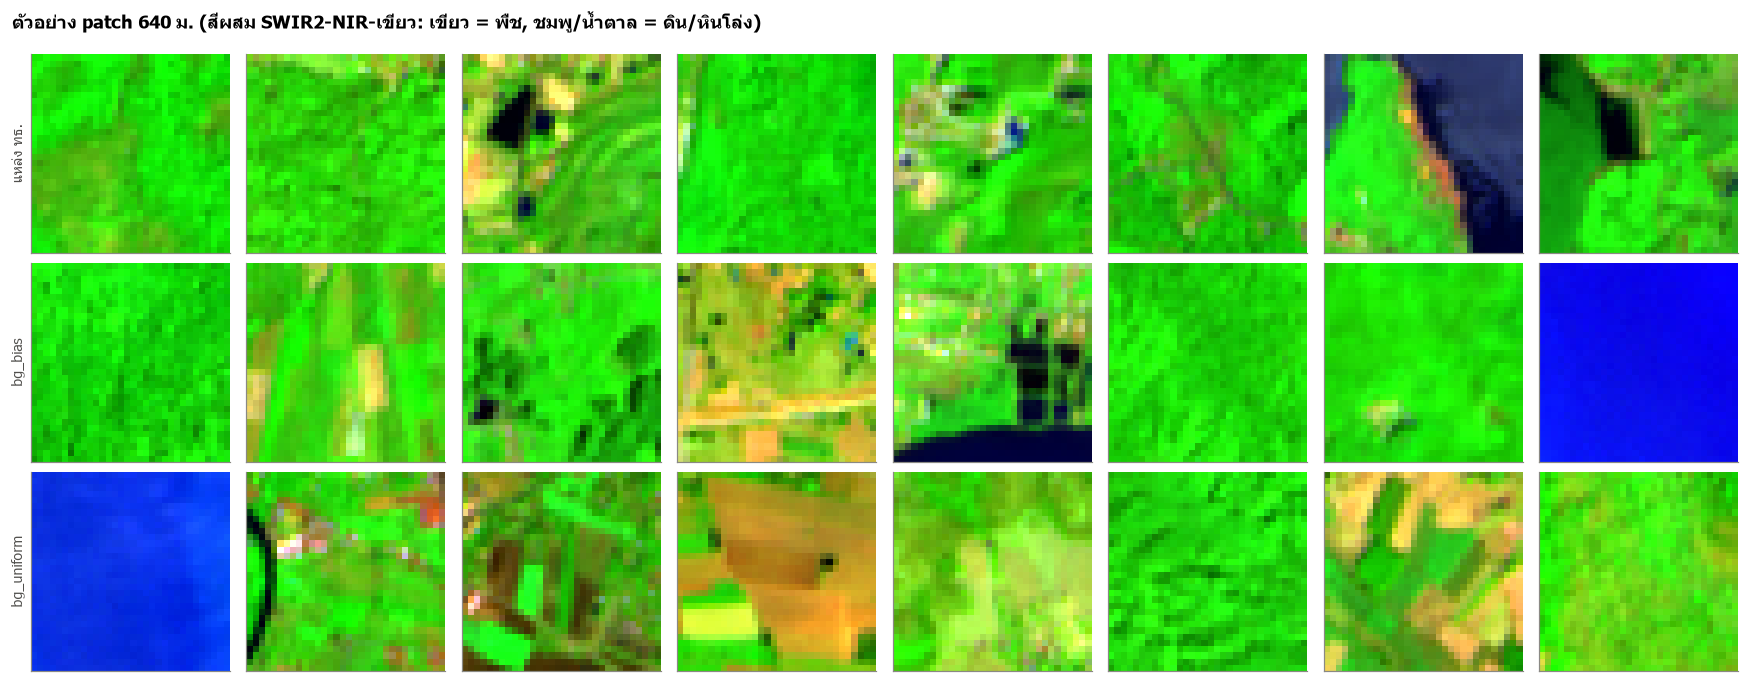

In [18]:
def show_patches(ids, title, ax_row):
    for ax, pid in zip(ax_row, ids):
        z = np.load(S2DIR / "patches" / f"{pid}.npz")["patch"].astype(float) * S2_SCALE + S2_OFFSET
        rgb = np.stack([z[5], z[3], z[1]], axis=-1)           # SWIR2 / NIR / green: แยกหิน-ดิน-พืช
        rgb = np.clip((rgb - np.percentile(rgb, 2)) / (np.percentile(rgb, 98) - np.percentile(rgb, 2) + 1e-6), 0, 1)
        ax.imshow(rgb)
        ax.set_xticks([]), ax.set_yticks([])
        ax.grid(False)
    ax_row[0].set_ylabel(title, fontsize=9)


rng = np.random.default_rng(0)
have = set(s2_df.point_id)
fig, axes = plt.subplots(3, 8, figsize=(16, 6.3))
for row, (src, title) in enumerate([("dmr_site", "แหล่ง ทธ."), ("bg_bias", "bg_bias"), ("bg_uniform", "bg_uniform")]):
    ids = rng.choice([p for p in points.loc[points.source.eq(src), "point_id"] if p in have], 8, replace=False)
    show_patches(ids, title, axes[row])
fig.suptitle("ตัวอย่าง patch 640 ม. (สีผสม SWIR2-NIR-เขียว: เขียว = พืช, ชมพู/น้ำตาล = ดิน/หินโล่ง)", x=0.01, ha="left", fontweight="bold")
plt.tight_layout()

## 6. ตรวจว่าโค้ดพันเจียใน `feature_lib` ให้ค่าเดียวกับ notebook 08

ขั้นทำนายจะคำนวณ feature พันเจียของพิกัดใหม่ด้วย `Pangea` ใน `feature_lib` จึงต้องได้ค่าเดียวกับที่ใช้ train ทุกค่า

In [19]:
ref = pd.read_parquet(FEAT / "pangea_features.parquet")
sample = points.sample(60, random_state=7)
pf = Pangea().features(sample.lon, sample.lat)
r = ref.set_index("point_id").loc[sample.point_id, pf.columns].reset_index(drop=True)
num = [c for c in pf.columns if pd.api.types.is_numeric_dtype(pf[c])]
max_diff = float((pf[num].astype(float) - r[num].astype(float)).abs().max().max())
same_cat = bool((pf.pg_me21_terrane.fillna("") == r.pg_me21_terrane.fillna("")).all())
print(f"ต่างกันสูงสุด {max_diff:.2e} | terrane ตรงกันทุกจุด: {same_cat}")
assert max_diff < 1e-6 and same_cat

ต่างกันสูงสุด 0.00e+00 | terrane ตรงกันทุกจุด: True


## 7. รวมทุกกลุ่ม feature

In [20]:
pg = ref.drop(columns=["source", "lon", "lat", "ref_id"])
allf = (points.merge(pg, on="point_id", how="left").merge(dem_df, on="point_id", how="left")
        .merge(geo_df, on="point_id", how="left").merge(s2_df, on="point_id", how="left"))
groups = {g: [c for c in allf.columns if c.startswith(p)] for g, p in FEATURE_GROUPS.items()}
cat_cols = [c for c in allf.columns if c[:3] in ("pg_", "geo", "oc_", "s2_", "dem") and not pd.api.types.is_numeric_dtype(allf[c])]
print({g: len(c) for g, c in groups.items()}, "| หมวดหมู่:", cat_cols)
miss = allf[[c for cs in groups.values() for c in cs]].isna().mean().mul(100)
print("คอลัมน์ที่มีค่าว่าง > 0%:", miss[miss > 0].round(2).to_dict())
allf.to_parquet(FEAT / "all_features.parquet", index=False)
(FEAT / "feature_groups.json").write_text(json.dumps({"groups": groups, "categorical": cat_cols}, ensure_ascii=False, indent=2), encoding="utf-8")
print("บันทึก all_features.parquet", allf.shape)

{'pangea': 119, 'dem': 15, 'geology': 30, 'outcrop': 5, 's2': 25} | หมวดหมู่: ['pg_sw18_terrane', 'pg_me21_terrane', 'geo_rock_sym', 'geo_era_old', 'geo_era_young', 'geo_rock_kind', 'oc_nearest_rock', 's2_item_id', 's2_date']
คอลัมน์ที่มีค่าว่าง > 0%: {'geo_share5_Precambrian': 0.08, 'geo_share5_Cambrian': 0.08, 'geo_share5_Ordovician': 0.08, 'geo_share5_Silurian': 0.08, 'geo_share5_Devonian': 0.08, 'geo_share5_Carboniferous': 0.08, 'geo_share5_Permian': 0.08, 'geo_share5_Triassic': 0.08, 'geo_share5_Jurassic': 0.08, 'geo_share5_Cretaceous': 0.08, 'geo_share5_Tertiary': 0.08, 'geo_share5_Quaternary': 0.08}
บันทึก all_features.parquet (10808, 199)


## 8. feature ไหนแยกแหล่งจริงออกจาก background ได้

วัดแต่ละ feature แยกกันด้วย AUC (0.5 = แยกไม่ได้, ห่างจาก 0.5 มาก = แยกได้ดี) เทียบแหล่ง ทธ. กับ background ทั้งสองแบบ
ถ้า feature แยกได้ดีกับ `bg_uniform` แต่ไม่ดีกับ `bg_bias` แปลว่ามันจับ "พื้นที่ที่คนไปสำรวจ" มากกว่าความต่างของพื้นที่จริง

background,AUC สูงสุด vs bg_uniform,AUC สูงสุด vs bg_bias
group,,
dem_,0.673,0.684
geo_,0.801,0.720
oc_,0.568,0.526
pg_,0.617,0.551
s2_,0.634,0.633


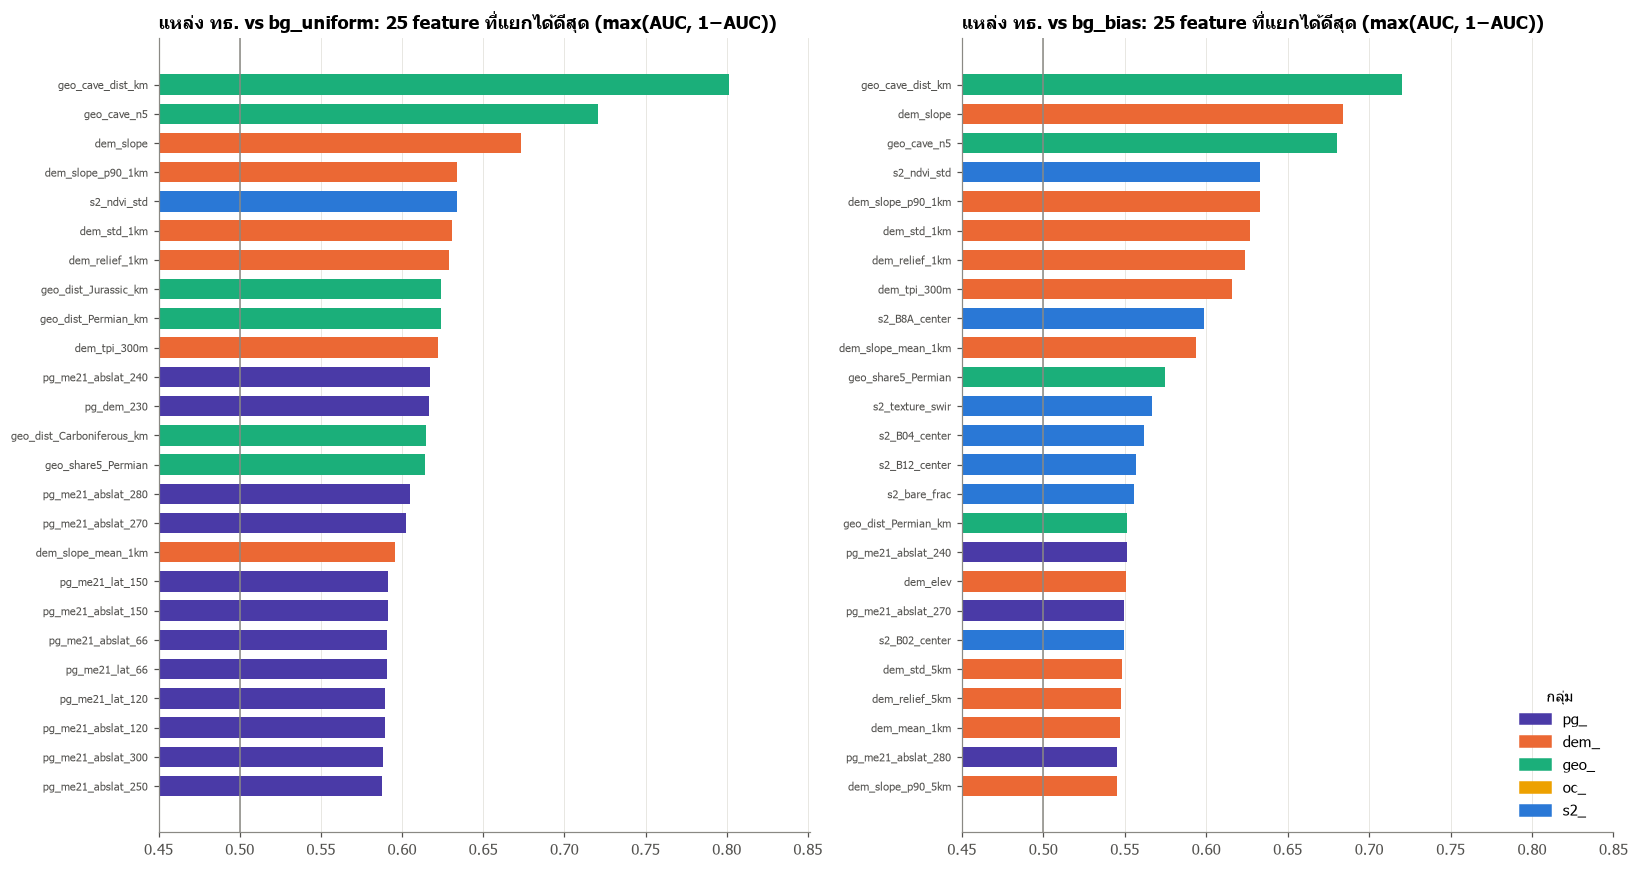

In [21]:
num_cols = [c for cs in groups.values() for c in cs if pd.api.types.is_numeric_dtype(allf[c]) and allf[c].nunique() > 2
            and not c.endswith(("_plate", "_begin_ma")) and not re.search(r"_lon_\d+$", c)]
rows = []
for bg in ["bg_uniform", "bg_bias"]:
    d = allf[allf.source.isin(["dmr_site", bg])]
    y = d.source.eq("dmr_site").astype(int)
    for c in num_cols:
        m = d[c].notna()
        if m.sum() > 50 and y[m].nunique() == 2:
            rows.append({"background": bg, "feature": c, "auc": roc_auc_score(y[m], d.loc[m, c])})
auc = pd.DataFrame(rows)
auc["strength"] = (auc.auc - 0.5).abs()
wide = auc.pivot(index="feature", columns="background", values="strength")
wide["group"] = [next(p for p in GROUP_COLOR if f.startswith(p)) for f in wide.index]

fig, axes = plt.subplots(1, 2, figsize=(15, 8))
for ax, bg in zip(axes, ["bg_uniform", "bg_bias"]):
    top = wide.sort_values(bg, ascending=False).head(25)[::-1]
    ax.barh(top.index, top[bg] + 0.5, left=0, color=[GROUP_COLOR[g] for g in top.group], height=0.7)
    ax.axvline(0.5, color=MUTED, lw=1)
    ax.set_xlim(0.45, max(0.85, top[bg].max() + 0.55))
    ax.set_title(f"แหล่ง ทธ. vs {bg}: 25 feature ที่แยกได้ดีสุด (max(AUC, 1−AUC))")
    ax.tick_params(axis="y", labelsize=7.5)
    ax.grid(axis="y", visible=False)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in GROUP_COLOR.values()]
axes[1].legend(handles, list(GROUP_COLOR), frameon=False, loc="lower right", title="กลุ่ม")
plt.tight_layout()
display(wide.groupby("group")[["bg_uniform", "bg_bias"]].max().add(0.5).round(3).rename(columns=lambda c: f"AUC สูงสุด vs {c}"))

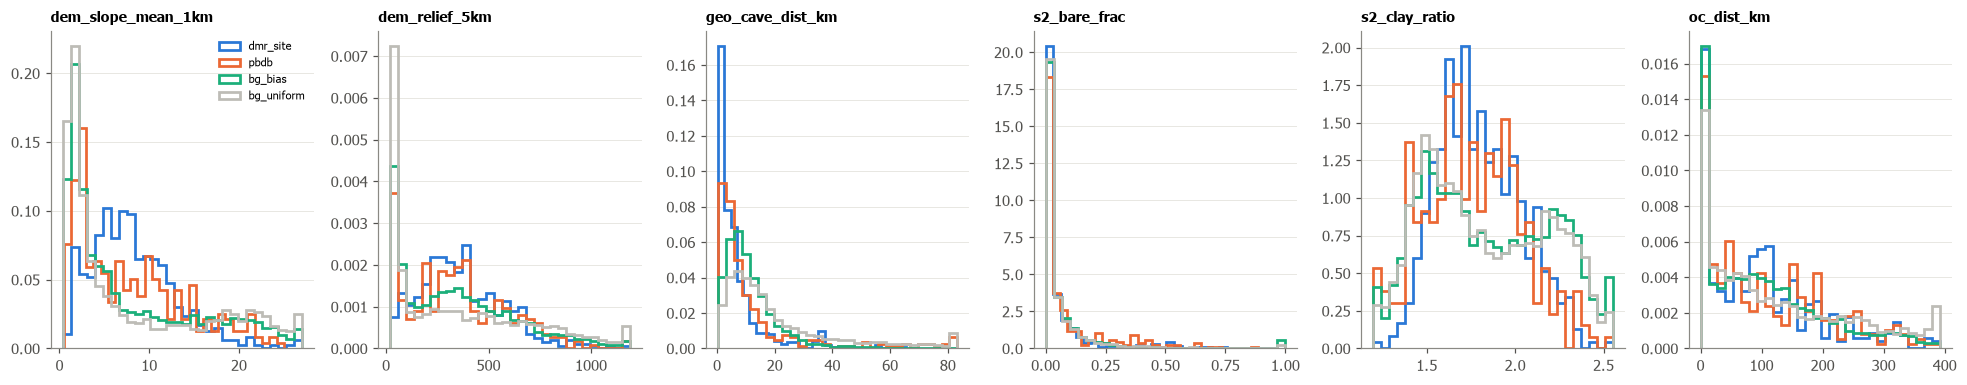

In [22]:
key = ["dem_slope_mean_1km", "dem_relief_5km", "geo_cave_dist_km", "s2_bare_frac", "s2_clay_ratio", "oc_dist_km"]
fig, axes = plt.subplots(1, len(key), figsize=(18, 3.6))
for ax, c in zip(axes, key):
    data = [allf.loc[allf.source.eq(s), c].dropna() for s in ["dmr_site", "pbdb", "bg_bias", "bg_uniform"]]
    lo, hi = np.nanpercentile(allf[c], [1, 99])
    for s, v in zip(["dmr_site", "pbdb", "bg_bias", "bg_uniform"], data):
        ax.hist(v.clip(lo, hi), bins=30, density=True, histtype="step", lw=1.8, color=SOURCE_COLOR[s], label=s)
    ax.set_title(c, fontsize=9)
    ax.grid(axis="x", visible=False)
axes[0].legend(frameon=False, fontsize=7)
plt.tight_layout()

## 9. สรุปขั้นที่ 2

**ข้อมูล**: feature ครบทุกจุด (10,808) — DEM ไม่มีค่าว่าง, Sentinel-2 ได้ภาพครบทุกจุด (ใช้ 188 ภาพ ส่วนใหญ่ ธ.ค.–ม.ค.),
มี 14 จุดที่หา patch เมฆ ≤ 5% ไม่ได้ (ใช้ patch ที่เมฆน้อยที่สุดแทน) และโค้ดพันเจียใน `feature_lib` ให้ค่าตรงกับ notebook 08 ทุกค่า

**feature ที่แยกแหล่งจริงออกจาก background ได้ดีสุด (ดูทีละตัว)**
- **ระยะถึงถ้ำ** (`geo_cave_dist_km`): AUC 0.80 vs `bg_uniform`, 0.72 vs `bg_bias` — แหล่งซากส่วนหนึ่งเป็นถ้ำในหินปูน
  **ข้อควรระวัง**: ทั้งรายชื่อแหล่งและข้อมูลถ้ำมาจากการสำรวจของ ทธ. ความสัมพันธ์นี้จึงอาจมีความลำเอียงของพื้นที่สำรวจปนอยู่
- **ความลาดชัน** (`dem_slope`, slope ในรัศมี 1 กม.): แหล่งอยู่บนพื้นลาดปานกลาง (5–15°) มากกว่าที่ราบลุ่ม
  ตรงกับ Block et al. 2016 ที่ใช้ slope เป็นตัวแทนการกัดเซาะที่ทำให้ซากโผล่
- **Sentinel-2**: ความแปรปรวนของพืชคลุมดินในพื้นที่ (`s2_ndvi_std`), ค่าสะท้อน NIR/SWIR ที่จุด และ SWIR1/SWIR2 ratio ช่วยได้ระดับปานกลาง
- **พันเจีย**: ช่วยระดับภูมิภาค (AUC ~0.6 กับ `bg_uniform`) แต่แทบไม่ช่วยกับ `bg_bias` ตามที่คาดในขั้นที่ 1 (เป็นข้อมูลระดับภูมิภาค)
- **หินโผล่** (`oc_`): AUC เพียง 0.53–0.57 และสัดส่วนจุดในจังหวัดที่สำรวจเท่ากันทุกกลุ่ม (33–41%) → แทบไม่มีข้อมูล ใช้ทดสอบ ablation ในขั้นโมเดลเท่านั้น

**`bg_bias` ทำให้งานยากขึ้นทุกกลุ่ม feature** (AUC สูงสุดลดลง) ซึ่งเป็นสิ่งที่ตั้งใจ: background อยู่ในพื้นที่ที่มีการสำรวจเหมือนแหล่ง
โมเดลต้องแยกด้วยลักษณะพื้นที่จริง ไม่ใช่ด้วย "ภูมิภาคที่คนไปสำรวจ"

**ข้อสังเกต**: background บางจุดตกในแหล่งน้ำ (ภาพสีน้ำเงิน) เพราะขอบเขตจังหวัดรวมพื้นที่น้ำด้วย ทำให้โมเดลเรียนว่า "น้ำ = ไม่มีซาก" ซึ่งถูกต้องตามจริง